# Pull × Air Quadrant Model — MLB (PAA + PAD_lac Edition)

Clean rebuild. Uses **LA-corrected PAD (PAD_lac)** as the primary direction
metric throughout, based on the validated finding that spray direction is
weakly determined by exit velocity alone (near-flat spray↔EV curvature) but
strongly determined by its relationship to launch angle (consistent, strong
spray↔LA slope for essentially every hitter tested). PAD_lac evaluates each
hitter's own `spray_pull ~ angle` regression at their own PAA, borrowing
PAA's much higher reliability to anchor the noisier direction axis.

**What was tried and ruled out** (kept in §9 as a documented record, not
re-run in the main pipeline): KDE-mode smoothing, joint 2D spray×angle
envelope estimation, foul-ball augmentation, and contact-depth "front contact"
estimation (which had a sign error the first time and turned out to be fully
redundant with the LA-correction once fixed). None beat the LA-correction;
several didn't beat a random baseline.

**Validated gains from PAD_raw → PAD_lac** (see §8 for the reproduction):
- Split-half reliability: 0.49→0.72 at BBE≥20, 0.60→0.84 at BBE≥100
- Agreement with measured attack_direction (bat tracking), held-out: r 0.489→0.637

**Pipeline**
1. Load Statcast, build BBE frame
2. Spray/pull/air flags, wOBAcon
3. PAA, PAD_raw, PAD_lac per batter-season
4. Quadrant assignment
5. **How the measures relate**: PAA vs PAD_raw vs PAD_lac vs measured attack_direction
6. Correlations vs Pull%/Air%/PullAir%
7. Feature profiles + quadrant classifiers + direct regression
8. Reliability: PAD_raw vs PAD_lac (fast joblib pipeline)
9. Ruled-out alternatives (KDE, joint 2D, fouls, contact-depth) — summary only
10. wOBAcon by quadrant, YoY stickiness, final deliverable

## 1. Imports & Config

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
from scipy.stats import spearmanr, pearsonr
from joblib import Parallel, delayed

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, cross_val_predict, train_test_split
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                             cohen_kappa_score, accuracy_score, r2_score)

pd.set_option("display.max_columns", 80)
pd.set_option("display.float_format", "{:.3f}".format)

PULL_CUTOFF_DEG = 15
AIR_LA_MIN      = 10

ANGLE_MIN, ANGLE_MAX = -30, 60
SPRAY_MIN, SPRAY_MAX = -45, 45
BIN_WIDTH        = 3
TOP_FRAC_PER_BIN = 0.20
TOP_N_METHOD2    = 15
MIN_BBE_LAC      = 30

MIN_BBE = 100

QUAD_ORDER  = ["Neither", "Pull only", "Air only", "Both"]
QUAD_COLORS = {"Neither": "#9E9E9E", "Pull only": "#E65100",
               "Air only": "#1565C0", "Both": "#1B5E20"}

print("Config OK")

Config OK


## 2. Metric Functions — PAA, Raw PAD, LA-Corrected PAD

Numpy-array machinery throughout, reused directly by the fast reliability
pipeline in §8.

In [2]:
def _envelope_peak_arrays(x, ev, x_min, x_max):
    """Marshall envelope: top-20%-per-bin parabola peak, averaged with the
    top-15-by-EV mean."""
    mask = (x >= x_min) & (x <= x_max) & ~np.isnan(x) & ~np.isnan(ev)
    x, ev = x[mask], ev[mask]
    if len(x) < 10:
        return np.nan

    k2 = min(TOP_N_METHOD2, max(3, int(np.ceil(0.2 * len(x)))))
    top2_idx = np.argpartition(ev, -k2)[-k2:] if len(ev) > k2 else np.arange(len(ev))
    method2 = x[top2_idx].mean()

    bins = np.arange(x_min, x_max + BIN_WIDTH, BIN_WIDTH)
    bin_idx = np.digitize(x, bins)
    env_x_parts, env_ev_parts = [], []
    for b_i in np.unique(bin_idx):
        m = bin_idx == b_i
        sub_x, sub_ev = x[m], ev[m]
        if len(sub_x) == 0:
            continue
        k = max(1, int(np.ceil(TOP_FRAC_PER_BIN * len(sub_x))))
        idx = np.argpartition(sub_ev, -k)[-k:] if len(sub_ev) > k else np.arange(len(sub_ev))
        env_x_parts.append(sub_x[idx])
        env_ev_parts.append(sub_ev[idx])

    if not env_x_parts:
        return method2
    env_x  = np.concatenate(env_x_parts)
    env_ev = np.concatenate(env_ev_parts)
    if len(env_x) < 5:
        return method2

    a, b, c = np.polyfit(env_x, env_ev, deg=2)
    if a < 0:
        v = -b / (2 * a)
        if x_min <= v <= x_max:
            method1 = v
        else:
            xs = np.linspace(x_min, x_max, 361)
            method1 = xs[np.argmax(np.polyval([a, b, c], xs))]
    else:
        method1 = env_x[np.argmax(env_ev)]

    return np.nanmean([method1, method2])


def _la_corrected_pad_arrays(la, sp, paa_val, min_n=MIN_BBE_LAC):
    """
    LA-corrected PAD: regress spray_pull on launch angle for this hitter,
    evaluate the fitted line at the hitter's own PAA. Routes direction
    estimation through the strong spray↔LA relationship rather than the
    weak, nearly-flat spray↔EV relationship raw PAD relies on.
    """
    mask = ~np.isnan(la) & ~np.isnan(sp)
    la_c, sp_c = la[mask], sp[mask]
    if len(la_c) < min_n or np.isnan(paa_val):
        return np.nan
    slope, intercept, *_ = stats.linregress(la_c, sp_c)
    return intercept + slope * paa_val


def compute_metrics_for_group(la, ev, sp):
    """Returns (PAA, PAD_raw, PAD_lac) for one batter-season's arrays."""
    paa     = _envelope_peak_arrays(la, ev, ANGLE_MIN, ANGLE_MAX)
    pad_raw = _envelope_peak_arrays(sp, ev, SPRAY_MIN, SPRAY_MAX)
    pad_lac = _la_corrected_pad_arrays(la, sp, paa)
    return paa, pad_raw, pad_lac

print("Metric functions defined")

Metric functions defined


## 3. Load Statcast (2024 + 2025) and Build BBE Frame

In [3]:
def load_statcast(cache_path):
    p = Path(cache_path)
    if p.exists():
        print(f"Loading {p} …")
        return pd.read_parquet(p)
    raise FileNotFoundError(f"{p} not found — build the cache first.")

raw24 = load_statcast("statcast_2024.parquet"); raw24["season"] = 2024
raw25 = load_statcast("statcast_2025.parquet"); raw25["season"] = 2025
raw = pd.concat([raw24, raw25], ignore_index=True)

mlb = raw[
    (raw["type"] == "X") &
    raw["launch_speed"].notna() &
    raw["launch_angle"].notna() &
    raw["hc_x"].notna() & raw["hc_y"].notna() &
    raw["stand"].notna() &
    raw["batter"].notna() &
    raw["events"].notna()
].copy()

print(f"MLB BBE rows: {len(mlb):,}   batters: {mlb['batter'].nunique():,}   "
      f"seasons: {sorted(mlb['season'].unique())}")

Loading statcast_2024.parquet …
Loading statcast_2025.parquet …
MLB BBE rows: 252,710   batters: 1,241   seasons: [np.int64(2024), np.int64(2025)]


## 4. Spray, Pull/Air Flags & wOBAcon

In [4]:
mlb["spray_deg"] = np.degrees(
    np.arctan((mlb["hc_x"] - 125.42) / (198.27 - mlb["hc_y"]))
) * 0.75
mlb["spray_pull"] = np.where(mlb["stand"] == "R", -mlb["spray_deg"], mlb["spray_deg"])
mlb["is_pull"]    = mlb["spray_pull"] > PULL_CUTOFF_DEG
mlb["is_air"]     = mlb["launch_angle"] >= AIR_LA_MIN
mlb["pull_air"]   = mlb["is_pull"] & mlb["is_air"]
mlb["hard_hit"]   = mlb["launch_speed"] >= 95

print(f"MLB league Pull%    : {mlb['is_pull'].mean():.3f}   (expect ≈ .36)")
print(f"MLB league Air%     : {mlb['is_air'].mean():.3f}")
print(f"MLB league PullAir% : {mlb['pull_air'].mean():.3f}")

WOBA_W = {"single": 0.88, "double": 1.25, "triple": 1.58, "home_run": 2.03}
mlb["woba_val"] = mlb["events"].map(WOBA_W).fillna(0.0)

MLB league Pull%    : 0.380   (expect ≈ .36)
MLB league Air%     : 0.560
MLB league PullAir% : 0.152


## 5. Batter-Season Aggregation — PAA, PAD_raw, PAD_lac

In [5]:
grp = mlb.groupby(["batter", "season"])

batter_df = grp.agg(
    n_bbe        = ("launch_speed", "size"),
    pull_pct     = ("is_pull",   "mean"),
    air_ball_pct = ("is_air",    "mean"),
    pull_air_pct = ("pull_air",  "mean"),
    mean_ev      = ("launch_speed","mean"),
    ev_90        = ("launch_speed", lambda s: s.quantile(0.90)),
    hard_hit_pct = ("hard_hit",  "mean"),
    wOBAcon      = ("woba_val",  "mean"),
    stand        = ("stand", lambda s: s.mode().iloc[0]),
).reset_index()

metric_rows = []
for (b, s), g in grp:
    la, ev, sp = (g["launch_angle"].to_numpy(), g["launch_speed"].to_numpy(),
                  g["spray_pull"].to_numpy())
    paa, pad_raw, pad_lac = compute_metrics_for_group(la, ev, sp)
    metric_rows.append({"batter": b, "season": s, "PAA": paa,
                        "PAD_raw": pad_raw, "PAD_lac": pad_lac})
batter_df = batter_df.merge(pd.DataFrame(metric_rows), on=["batter", "season"])
batter_df["is_L"] = (batter_df["stand"] == "L").astype(int)

numeric_cols = batter_df.select_dtypes(include="number").columns
batter_df[numeric_cols] = batter_df[numeric_cols].astype("float64")

qual = batter_df[(batter_df["n_bbe"] >= MIN_BBE) &
                 batter_df["PAA"].notna() &
                 batter_df["PAD_lac"].notna()].copy()

print(f"Batter-seasons total: {len(batter_df)}   qualified (≥{MIN_BBE} BBE): {len(qual)}")
print(qual[["PAA", "PAD_raw", "PAD_lac", "pull_pct",
            "air_ball_pct", "pull_air_pct"]].describe().round(3))

Batter-seasons total: 1862   qualified (≥100 BBE): 800
          PAA  PAD_raw  PAD_lac  pull_pct  air_ball_pct  pull_air_pct
count 800.000  800.000  800.000   800.000       800.000       800.000
mean   11.376   11.183    4.550     0.381         0.560         0.152
std     5.421    5.707    3.085     0.062         0.071         0.052
min    -7.534   -6.805   -5.495     0.190         0.364         0.031
25%     8.133    7.432    2.463     0.338         0.512         0.118
50%    11.457   11.189    4.540     0.383         0.560         0.146
75%    14.915   14.507    6.608     0.424         0.608         0.185
max    28.618   32.932   12.635     0.565         0.770         0.361


## 6. Quadrant Assignment

Median cuts — Pull%: 0.383   Air%: 0.560

quadrant
Neither      246
Pull only    154
Air only     154
Both         246
Name: count, dtype: int64


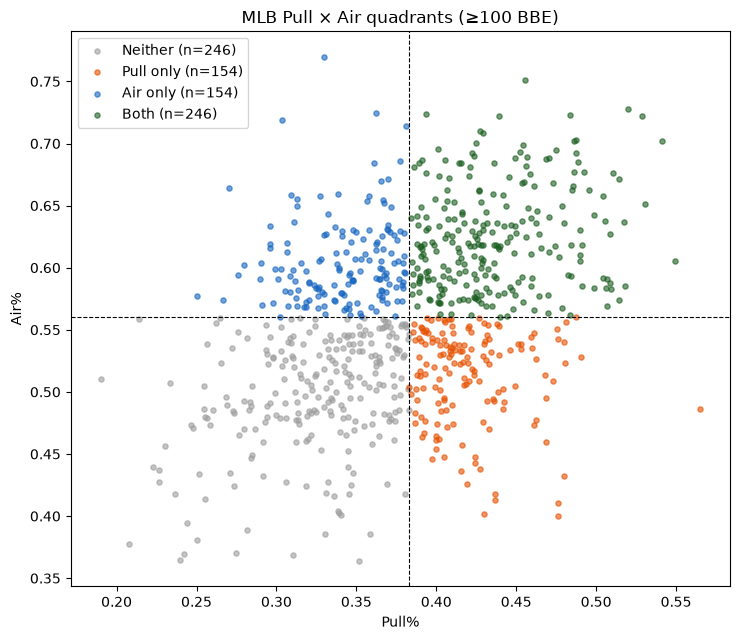

In [6]:
pull_cut = qual["pull_pct"].median()
air_cut  = qual["air_ball_pct"].median()

qual["quadrant"] = np.select(
    [(qual["pull_pct"] >= pull_cut) & (qual["air_ball_pct"] >= air_cut),
     (qual["pull_pct"] >= pull_cut),
     (qual["air_ball_pct"] >= air_cut)],
    ["Both", "Pull only", "Air only"],
    "Neither"
)

print(f"Median cuts — Pull%: {pull_cut:.3f}   Air%: {air_cut:.3f}\n")
print(qual["quadrant"].value_counts().reindex(QUAD_ORDER))

fig, ax = plt.subplots(figsize=(7.5, 6.5))
for q in QUAD_ORDER:
    sub = qual[qual["quadrant"] == q]
    ax.scatter(sub["pull_pct"], sub["air_ball_pct"], s=14, alpha=0.6,
               color=QUAD_COLORS[q], label=f"{q} (n={len(sub)})")
ax.axvline(pull_cut, color="black", lw=0.8, ls="--")
ax.axhline(air_cut,  color="black", lw=0.8, ls="--")
ax.set_xlabel("Pull%"); ax.set_ylabel("Air%")
ax.set_title(f"MLB Pull × Air quadrants (≥{MIN_BBE} BBE)")
ax.legend(); plt.tight_layout(); plt.show()

## 7. How the Measures Relate — PAA, PAD_raw, PAD_lac, Measured Attack Direction

The core relationship map. PAD_lac is *constructed* from PAA (evaluating each
hitter's own spray~LA line at their PAA), so PAA↔PAD_lac correlation is
expected to be nonzero by design — the question is whether PAD_lac still adds
information beyond that mechanical link, and whether it agrees with the
bat-tracking ground truth better than raw PAD does.

── Pairwise Pearson correlation ──
          PAA  PAD_raw  PAD_lac
PAA     1.000    0.237    0.190
PAD_raw 0.237    1.000    0.586
PAD_lac 0.190    0.586    1.000


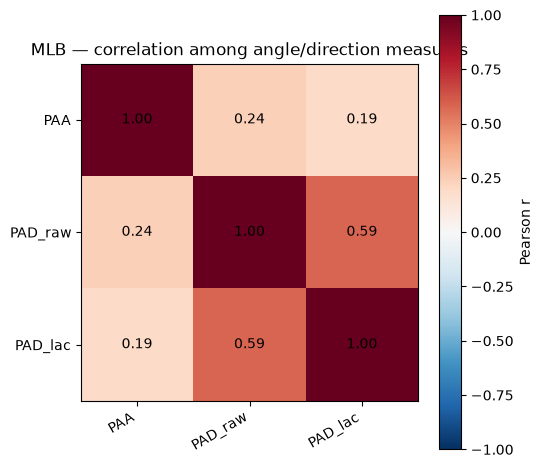

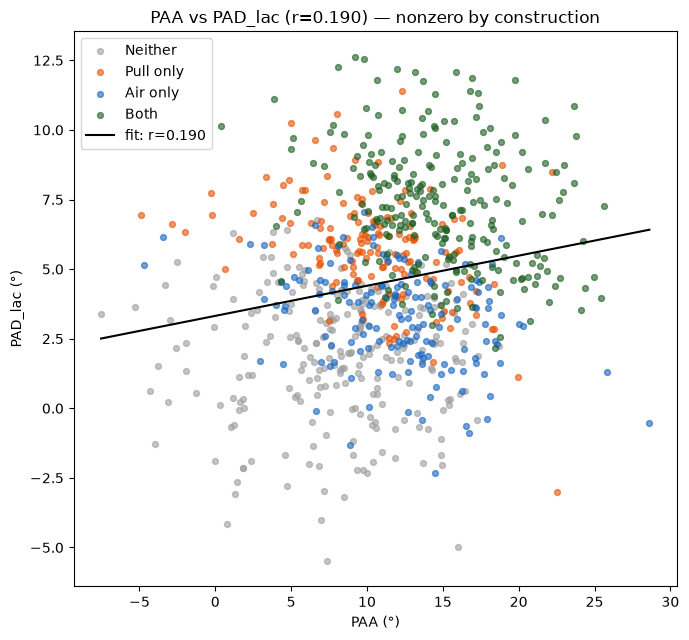


PAD_lac variance explained by PAA: r² = 0.036
PAD_lac residual std (PAA-independent component): 3.03°
(this residual is what PAD_lac adds beyond a pure PAA-driven prediction)


In [7]:
# ── Pairwise correlations among all direction/angle measures ─────────────────
metrics_for_corr = ["PAA", "PAD_raw", "PAD_lac"]
corr_matrix = qual[metrics_for_corr].corr()
print("── Pairwise Pearson correlation ──")
print(corr_matrix.round(3).to_string())

fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.imshow(corr_matrix.to_numpy(dtype=np.float64), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(metrics_for_corr))); ax.set_xticklabels(metrics_for_corr, rotation=30, ha="right")
ax.set_yticks(range(len(metrics_for_corr))); ax.set_yticklabels(metrics_for_corr)
for i in range(len(metrics_for_corr)):
    for j in range(len(metrics_for_corr)):
        ax.text(j, i, f"{corr_matrix.iloc[i,j]:.2f}", ha="center", va="center", fontsize=10)
plt.colorbar(im, ax=ax, label="Pearson r")
ax.set_title("MLB — correlation among angle/direction measures")
plt.tight_layout(); plt.show()

# ── PAA vs PAD_lac scatter (mechanical dependency, by construction) ──────────
fig, ax = plt.subplots(figsize=(7, 6.5))
for q in QUAD_ORDER:
    sub = qual[qual["quadrant"] == q]
    ax.scatter(sub["PAA"], sub["PAD_lac"], s=18, alpha=0.6, color=QUAD_COLORS[q], label=q)
slope, intercept, r, p, se = stats.linregress(qual["PAA"], qual["PAD_lac"])
xs = np.linspace(qual["PAA"].min(), qual["PAA"].max(), 100)
ax.plot(xs, intercept + slope * xs, color="black", linewidth=1.5, label=f"fit: r={r:.3f}")
ax.set_xlabel("PAA (°)"); ax.set_ylabel("PAD_lac (°)")
ax.set_title(f"PAA vs PAD_lac (r={r:.3f}) — nonzero by construction")
ax.legend(); plt.tight_layout(); plt.show()

# ── PAD_lac residualized against PAA: the PAA-independent component ──────────
qual["PAD_lac_resid"] = qual["PAD_lac"] - (intercept + slope * qual["PAA"])
print(f"\nPAD_lac variance explained by PAA: r² = {r**2:.3f}")
print(f"PAD_lac residual std (PAA-independent component): {qual['PAD_lac_resid'].std():.2f}°")
print("(this residual is what PAD_lac adds beyond a pure PAA-driven prediction)")

### 7b. Agreement with Measured Attack Direction (bat-tracking ground truth)

The decisive comparison: does PAD_lac agree with Statcast's measured swing
direction better than raw PAD does? Sign convention on `attack_direction` is
derived empirically per handedness (never assumed) — opposite-signed
correlations by hand indicate a stand-relative convention, not absolute.

  RHB: attack_direction vs spray_deg  r = +0.532
  LHB: attack_direction vs spray_deg  r = -0.489

PAD_raw vs measured attack_direction: r = 0.518   mean bias = +11.76°
PAD_lac vs measured attack_direction: r = 0.622   mean bias = +5.12°

Held-out r — PAD_raw alone:          0.532
Held-out r — PAD_raw + PAD_lac blend: 0.641


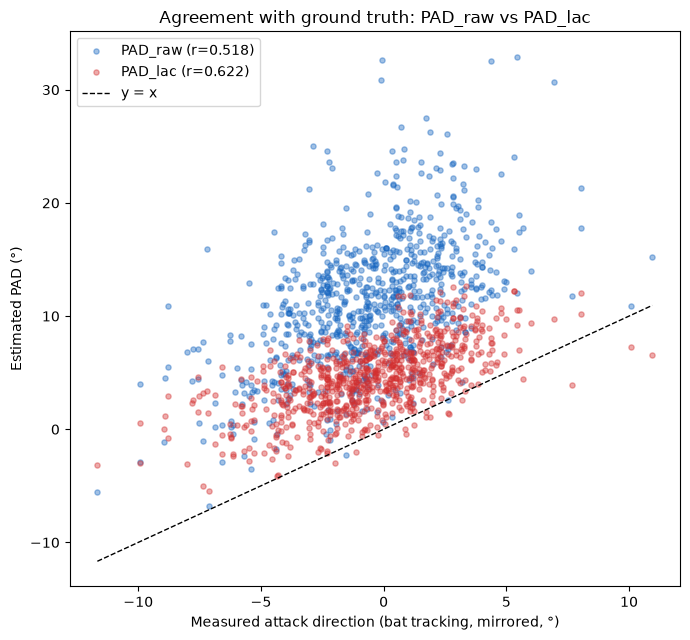

In [8]:
ad_bbe = raw[
    (raw["type"] == "X") &
    raw["attack_direction"].notna() &
    raw["hc_x"].notna() & raw["hc_y"].notna() &
    raw["stand"].notna()
].copy()
ad_bbe["spray_deg"] = np.degrees(
    np.arctan((ad_bbe["hc_x"] - 125.42) / (198.27 - ad_bbe["hc_y"]))
) * 0.75

# Physically implausible outlier filter
ad_bbe = ad_bbe[ad_bbe["attack_direction"].between(-50, 50)]
ad_bbe = ad_bbe[ad_bbe["spray_deg"].between(-45, 45)]

# Empirical sign convention per handedness
signs = {}
for side in ["R", "L"]:
    sub = ad_bbe[ad_bbe["stand"] == side]
    r_sign = sub[["attack_direction", "spray_deg"]].corr().iloc[0, 1]
    signs[side] = np.sign(r_sign)
    print(f"  {side}HB: attack_direction vs spray_deg  r = {r_sign:+.3f}")

ad_bbe["ad_pull"] = np.where(
    ad_bbe["stand"] == "R",
    -ad_bbe["attack_direction"] * signs["R"],
     ad_bbe["attack_direction"] * signs["L"],
)

ad_batter_mean = (
    ad_bbe.groupby("batter")
    .agg(ad_pull_mean=("ad_pull", "mean"), n_swings=("ad_pull", "count"))
    .reset_index()
)

# ── Compare PAD_raw and PAD_lac agreement with MAD ────────────────────────────
combined = qual.merge(
    ad_batter_mean[ad_batter_mean["n_swings"] >= 100][["batter", "ad_pull_mean"]],
    on="batter", how="inner"
).dropna(subset=["PAD_raw", "PAD_lac", "ad_pull_mean"])

r_raw, _ = pearsonr(combined["PAD_raw"], combined["ad_pull_mean"])
r_lac, _ = pearsonr(combined["PAD_lac"], combined["ad_pull_mean"])
bias_raw = (combined["PAD_raw"] - combined["ad_pull_mean"]).mean()
bias_lac = (combined["PAD_lac"] - combined["ad_pull_mean"]).mean()

print(f"\nPAD_raw vs measured attack_direction: r = {r_raw:.3f}   mean bias = {bias_raw:+.2f}°")
print(f"PAD_lac vs measured attack_direction: r = {r_lac:.3f}   mean bias = {bias_lac:+.2f}°")

# Held-out validation (avoids overstating in-sample agreement)
X_simple = combined[["PAD_raw", "PAD_lac"]].to_numpy(dtype=np.float64)
y_simple = combined["ad_pull_mean"].to_numpy(dtype=np.float64)
tr_idx, te_idx = train_test_split(np.arange(len(combined)), test_size=0.3, random_state=42)

r_holdout_raw = pearsonr(combined["PAD_raw"].to_numpy()[te_idx], y_simple[te_idx])[0]
blend = LinearRegression().fit(X_simple[tr_idx], y_simple[tr_idx])
r_holdout_lac = pearsonr(blend.predict(X_simple[te_idx]), y_simple[te_idx])[0]

print(f"\nHeld-out r — PAD_raw alone:          {r_holdout_raw:.3f}")
print(f"Held-out r — PAD_raw + PAD_lac blend: {r_holdout_lac:.3f}")

fig, ax = plt.subplots(figsize=(7, 6.5))
ax.scatter(combined["ad_pull_mean"], combined["PAD_raw"], s=14, alpha=0.4,
          color="#1565C0", label=f"PAD_raw (r={r_raw:.3f})")
ax.scatter(combined["ad_pull_mean"], combined["PAD_lac"], s=14, alpha=0.4,
          color="#D32F2F", label=f"PAD_lac (r={r_lac:.3f})")
lims = [combined["ad_pull_mean"].min(), combined["ad_pull_mean"].max()]
ax.plot(lims, lims, "k--", linewidth=1, label="y = x")
ax.set_xlabel("Measured attack direction (bat tracking, mirrored, °)")
ax.set_ylabel("Estimated PAD (°)")
ax.set_title("Agreement with ground truth: PAD_raw vs PAD_lac")
ax.legend(); plt.tight_layout(); plt.show()

### 7c. Calibrate PAD_lac to the MAD Scale

Calibration fit: MAD ≈ -3.260 + 0.591 × PAD_lac
r = 0.622   (should match the r=0.622 already found — calibration doesn't change correlation)

Mean bias before calibration: +5.12°
Mean bias after calibration:  -0.00°


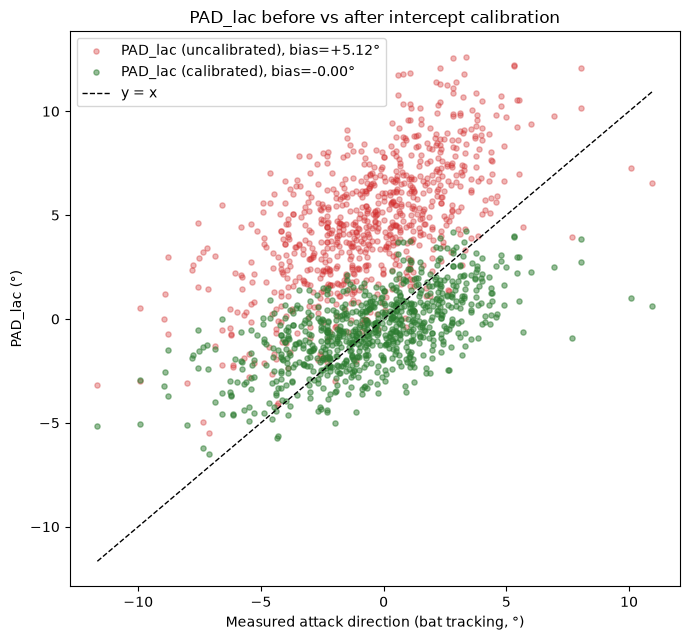

In [9]:
# ── Calibrate PAD_lac to MAD scale (fix residual intercept offset) ──────────
slope_cal, intercept_cal, r_cal, p_cal, se_cal = stats.linregress(
    combined["PAD_lac"], combined["ad_pull_mean"]
)
print(f"Calibration fit: MAD ≈ {intercept_cal:.3f} + {slope_cal:.3f} × PAD_lac")
print(f"r = {r_cal:.3f}   (should match the r=0.622 already found — calibration doesn't change correlation)")

# Apply calibration to the full qual set (not just the MAD-validation subset)
qual["PAD_lac_cal"] = intercept_cal + slope_cal * qual["PAD_lac"]

# Verify: does the calibrated version now sit on y=x against ground truth?
combined["PAD_lac_cal"] = intercept_cal + slope_cal * combined["PAD_lac"]
bias_before = (combined["PAD_lac"]     - combined["ad_pull_mean"]).mean()
bias_after  = (combined["PAD_lac_cal"] - combined["ad_pull_mean"]).mean()
print(f"\nMean bias before calibration: {bias_before:+.2f}°")
print(f"Mean bias after calibration:  {bias_after:+.2f}°")

fig, ax = plt.subplots(figsize=(7, 6.5))
ax.scatter(combined["ad_pull_mean"], combined["PAD_lac"],     s=14, alpha=0.35,
          color="#D32F2F", label=f"PAD_lac (uncalibrated), bias={bias_before:+.2f}°")
ax.scatter(combined["ad_pull_mean"], combined["PAD_lac_cal"], s=14, alpha=0.5,
          color="#2E7D32", label=f"PAD_lac (calibrated), bias={bias_after:+.2f}°")
lims = [combined["ad_pull_mean"].min(), combined["ad_pull_mean"].max()]
ax.plot(lims, lims, "k--", linewidth=1, label="y = x")
ax.set_xlabel("Measured attack direction (bat tracking, °)")
ax.set_ylabel("PAD_lac (°)")
ax.set_title("PAD_lac before vs after intercept calibration")
ax.legend(); plt.tight_layout(); plt.show()

### 7d. Agreement with Measured Attack Angle, and Calibration

PAA vs measured attack_angle (n=796): r = 0.735   mean bias = +2.97°


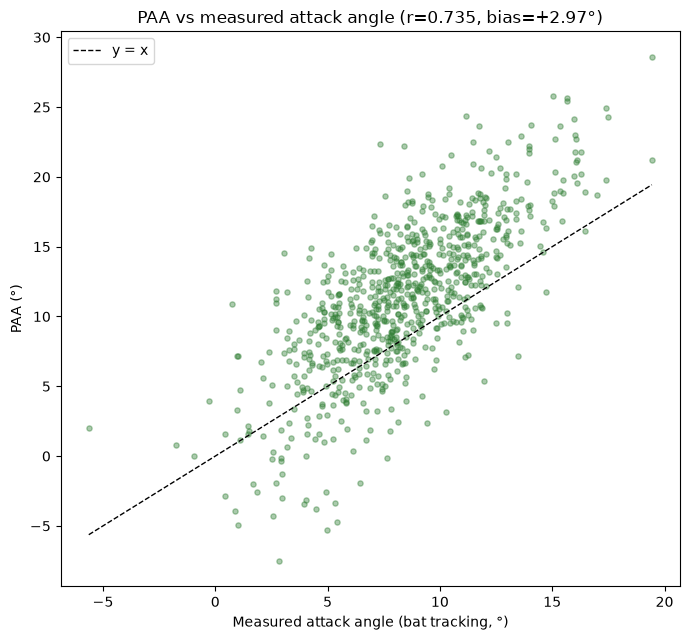


Calibration fit: measured_AA ≈ 3.080 + 0.461 × PAA
Held-out bias after calibration: -0.27°
(uncalibrated bias was +2.97°)


In [10]:
# ── PAA vs measured attack_angle (bat tracking ground truth) ────────────────
aa_bbe = raw[
    (raw["type"] == "X") &
    raw["attack_angle"].notna() &
    raw["batter"].notna()
].copy()

aa_batter_mean = (
    aa_bbe.groupby("batter")
    .agg(aa_measured_mean=("attack_angle", "mean"), n_swings=("attack_angle", "count"))
    .reset_index()
)

combined_aa = qual.merge(
    aa_batter_mean[aa_batter_mean["n_swings"] >= 100][["batter", "aa_measured_mean"]],
    on="batter", how="inner"
).dropna(subset=["PAA", "aa_measured_mean"])

r_paa, p_paa = pearsonr(combined_aa["PAA"], combined_aa["aa_measured_mean"])
bias_paa = (combined_aa["PAA"] - combined_aa["aa_measured_mean"]).mean()
print(f"PAA vs measured attack_angle (n={len(combined_aa)}): r = {r_paa:.3f}   mean bias = {bias_paa:+.2f}°")

fig, ax = plt.subplots(figsize=(7, 6.5))
ax.scatter(combined_aa["aa_measured_mean"], combined_aa["PAA"], s=14, alpha=0.4, color="#2E7D32")
lims = [combined_aa["aa_measured_mean"].min(), combined_aa["aa_measured_mean"].max()]
ax.plot(lims, lims, "k--", linewidth=1, label="y = x")
ax.set_xlabel("Measured attack angle (bat tracking, °)")
ax.set_ylabel("PAA (°)")
ax.set_title(f"PAA vs measured attack angle (r={r_paa:.3f}, bias={bias_paa:+.2f}°)")
ax.legend(); plt.tight_layout(); plt.show()

# ── Held-out calibration check (same protocol as PAD_lac) ────────────────────
tr_idx, te_idx = train_test_split(np.arange(len(combined_aa)), test_size=0.3, random_state=42)

slope_aa, intercept_aa, r_cal_aa, *_ = stats.linregress(
    combined_aa["PAA"].to_numpy()[tr_idx], combined_aa["aa_measured_mean"].to_numpy()[tr_idx]
)
pred_test_aa = intercept_aa + slope_aa * combined_aa["PAA"].to_numpy()[te_idx]
bias_test_aa = (pred_test_aa - combined_aa["aa_measured_mean"].to_numpy()[te_idx]).mean()

print(f"\nCalibration fit: measured_AA ≈ {intercept_aa:.3f} + {slope_aa:.3f} × PAA")
print(f"Held-out bias after calibration: {bias_test_aa:+.2f}°")
print(f"(uncalibrated bias was {bias_paa:+.2f}°)")

#### Full-sample calibration for PAA (parallels §7c's PAD_lac calibration)

§7d above fit the PAA calibration on a held-out split to validate it honestly.
This cell refits on the *full* `combined_aa` sample (same pattern as §7c) so
`PAA_cal` exists as a column — needed for the residual-vs-BBE analysis below,
which wants one consistent "predicted" value per metric.

In [11]:
slope_cal_aa, intercept_cal_aa, r_cal_aa2, p_cal_aa2, se_cal_aa2 = stats.linregress(
    combined_aa["PAA"], combined_aa["aa_measured_mean"]
)
print(f"Full-sample calibration: measured_AA ≈ {intercept_cal_aa:.3f} + {slope_cal_aa:.3f} × PAA")
print(f"r = {r_cal_aa2:.3f}   (matches §7d's r={r_paa:.3f} — calibration doesn't change correlation)")

qual["PAA_cal"] = intercept_cal_aa + slope_cal_aa * qual["PAA"]
combined_aa["PAA_cal"] = intercept_cal_aa + slope_cal_aa * combined_aa["PAA"]

bias_before_aa = (combined_aa["PAA"]     - combined_aa["aa_measured_mean"]).mean()
bias_after_aa  = (combined_aa["PAA_cal"] - combined_aa["aa_measured_mean"]).mean()
print(f"\nMean bias before calibration: {bias_before_aa:+.2f}°")
print(f"Mean bias after calibration:  {bias_after_aa:+.2f}°")

Full-sample calibration: measured_AA ≈ 3.261 + 0.452 × PAA
r = 0.735   (matches §7d's r=0.735 — calibration doesn't change correlation)

Mean bias before calibration: +2.97°
Mean bias after calibration:  +0.00°


### 7e. Why the LA-Correction Works (spray↔EV vs spray↔LA)

Sample of qualified hitters: top row is spray vs EV (the axis raw PAD relies
on — expect near-flat), bottom row is spray vs launch angle (the axis
PAD_lac relies on — expect a strong, consistent negative slope). This is
the mechanism behind both §7b/§7c's results above.

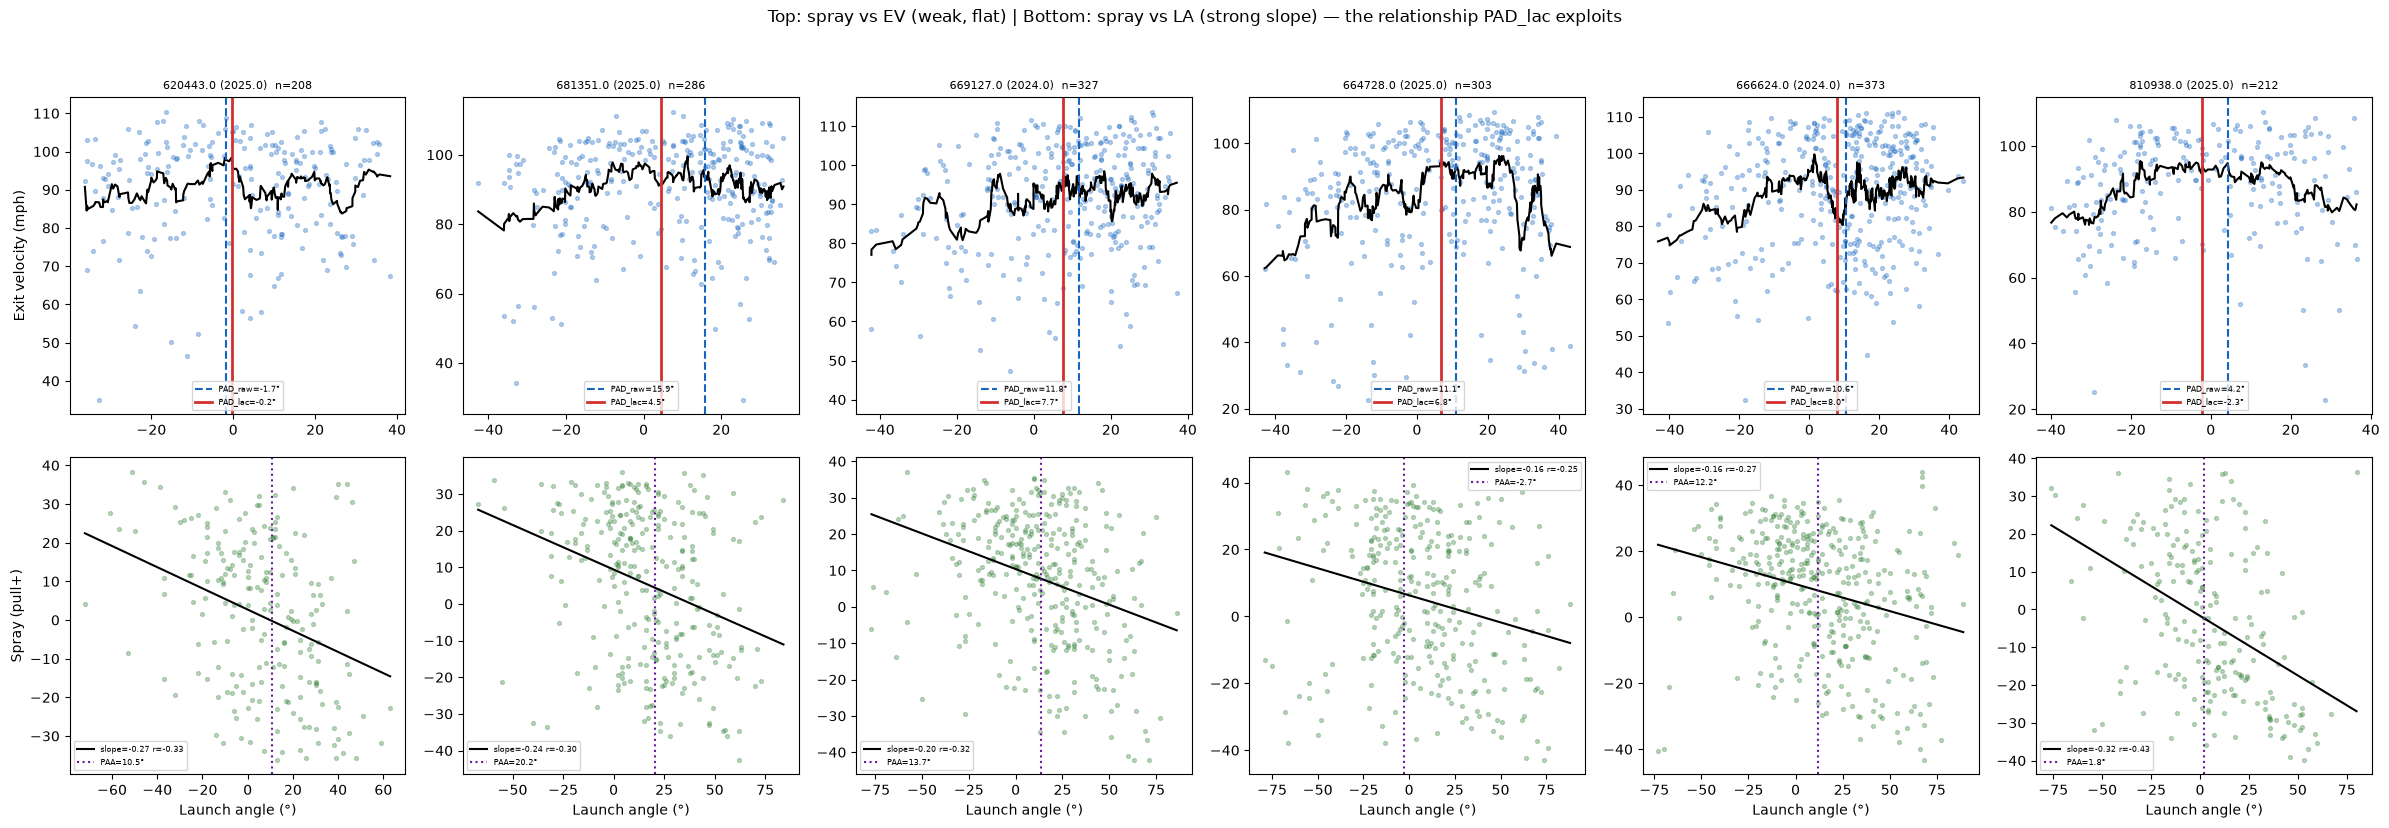

In [12]:
sample_batters = (qual[qual["n_bbe"] >= 200]
                  .sample(min(6, len(qual)), random_state=3)[["batter", "season"]]
                  .itertuples(index=False))

fig, axes = plt.subplots(2, 6, figsize=(24, 8))
for col, (b, s) in enumerate(sample_batters):
    g = mlb[(mlb["batter"] == b) & (mlb["season"] == s)].dropna(
        subset=["spray_pull", "launch_speed", "launch_angle"])
    g = g[g["spray_pull"].between(SPRAY_MIN, SPRAY_MAX)]
    if len(g) < 50:
        continue

    la, ev, sp = g["launch_angle"].to_numpy(), g["launch_speed"].to_numpy(), g["spray_pull"].to_numpy()
    paa, pad_raw, pad_lac = compute_metrics_for_group(la, ev, sp)
    g_sorted = g.sort_values("spray_pull")

    ax1 = axes[0, col]
    ax1.scatter(g["spray_pull"], g["launch_speed"], s=8, alpha=0.3, color="#1565C0")
    roll = g_sorted["launch_speed"].rolling(15, center=True, min_periods=5).mean()
    ax1.plot(g_sorted["spray_pull"], roll, color="black", linewidth=1.5)
    ax1.axvline(pad_raw, color="#1565C0", linestyle="--", label=f"PAD_raw={pad_raw:.1f}°")
    ax1.axvline(pad_lac, color="#D32F2F", linewidth=2, label=f"PAD_lac={pad_lac:.1f}°")
    ax1.set_title(f"{b} ({s})  n={len(g)}", fontsize=8)
    ax1.legend(fontsize=6, loc="lower center")
    if col == 0: ax1.set_ylabel("Exit velocity (mph)")

    ax2 = axes[1, col]
    ax2.scatter(g["launch_angle"], g["spray_pull"], s=8, alpha=0.3, color="#2E7D32")
    slope_i, intercept_i, r_i, *_ = stats.linregress(g["launch_angle"], g["spray_pull"])
    xs = np.linspace(g["launch_angle"].min(), g["launch_angle"].max(), 50)
    ax2.plot(xs, intercept_i + slope_i * xs, color="black", linewidth=1.5,
             label=f"slope={slope_i:.2f} r={r_i:.2f}")
    ax2.axvline(paa, color="#6A1B9A", linestyle=":", label=f"PAA={paa:.1f}°")
    ax2.set_xlabel("Launch angle (°)")
    ax2.legend(fontsize=6)
    if col == 0: ax2.set_ylabel("Spray (pull+)")

plt.suptitle("Top: spray vs EV (weak, flat) | Bottom: spray vs LA (strong slope) — "
             "the relationship PAD_lac exploits", y=1.03)
plt.tight_layout(); plt.show()

### 7f. Does Sample Size (BBE) Explain the Residual?

Both PAA and PAD_lac are envelope statistics computed from a limited number
of batted balls per hitter-season — the split-half reliability curves
(§12) already show their *self-consistency* improves with more BBE. This
section asks the same question a different way, using an **independent**
ground truth (measured bat-tracking) rather than comparing the metric to
itself: does a hitter's `n_bbe` predict how far his PAA/PAD_lac lands from
his own measured attack angle/direction?

Two separate questions, on purpose:
- **Signed residual vs BBE** — should show close to *no* relationship. If
  it did, that would mean the calibration itself is biased differently at
  different sample sizes, which would be a real problem (a systematic drift,
  not noise).
- **Absolute residual vs BBE** — this is the one we actually expect to see
  shrink. More BBE per hitter should mean a tighter envelope estimate and a
  smaller gap from the measured value, mirroring the split-half reliability
  story via a completely independent check.

In [13]:
# ── Build a single per-metric residual table with n_bbe attached ─────────────
# combined / combined_aa already carry n_bbe from `qual` — no extra merge needed.
resid_pad = combined[["batter", "n_bbe", "PAD_lac", "PAD_lac_cal", "ad_pull_mean"]].copy()
resid_pad["resid"]      = resid_pad["PAD_lac_cal"] - resid_pad["ad_pull_mean"]
resid_pad["abs_resid"]  = resid_pad["resid"].abs()

resid_paa = combined_aa[["batter", "n_bbe", "PAA", "PAA_cal", "aa_measured_mean"]].copy()
resid_paa["resid"]     = resid_paa["PAA_cal"] - resid_paa["aa_measured_mean"]
resid_paa["abs_resid"] = resid_paa["resid"].abs()

print(f"PAD_lac residual table: n={len(resid_pad)}   PAA residual table: n={len(resid_paa)}")

# ── Signed residual vs BBE (expect ~0 — checking for bias drift) ────────────
print("\n── Signed residual vs n_bbe (expect near-zero — flags calibration bias drift) ──")
for name, df_r in [("PAA", resid_paa), ("PAD_lac", resid_pad)]:
    r_signed, p_signed = pearsonr(df_r["n_bbe"], df_r["resid"])
    print(f"  {name:<8} r = {r_signed:+.3f}   (p={p_signed:.2e})")

# ── |Residual| vs BBE, several transforms — this is the main question ───────
print("\n── |Residual| vs n_bbe (the expected-to-shrink relationship) ──")
for name, df_r in [("PAA", resid_paa), ("PAD_lac", resid_pad)]:
    r_lin, p_lin = pearsonr(df_r["n_bbe"], df_r["abs_resid"])
    r_log, p_log = pearsonr(np.log(df_r["n_bbe"]), df_r["abs_resid"])
    r_inv, p_inv = pearsonr(1 / np.sqrt(df_r["n_bbe"]), df_r["abs_resid"])
    print(f"  {name}:")
    print(f"    |resid| vs n_bbe          r = {r_lin:+.3f}  (p={p_lin:.2e})")
    print(f"    |resid| vs log(n_bbe)     r = {r_log:+.3f}  (p={p_log:.2e})")
    print(f"    |resid| vs 1/sqrt(n_bbe)  r = {r_inv:+.3f}  (p={p_inv:.2e})  "
          f"← matches the shape reliability theory predicts (SE ∝ 1/√n)")

PAD_lac residual table: n=791   PAA residual table: n=796

── Signed residual vs n_bbe (expect near-zero — flags calibration bias drift) ──
  PAA      r = -0.054   (p=1.26e-01)
  PAD_lac  r = -0.032   (p=3.71e-01)

── |Residual| vs n_bbe (the expected-to-shrink relationship) ──
  PAA:
    |resid| vs n_bbe          r = -0.068  (p=5.56e-02)
    |resid| vs log(n_bbe)     r = -0.072  (p=4.22e-02)
    |resid| vs 1/sqrt(n_bbe)  r = +0.073  (p=4.06e-02)  ← matches the shape reliability theory predicts (SE ∝ 1/√n)
  PAD_lac:
    |resid| vs n_bbe          r = -0.131  (p=2.18e-04)
    |resid| vs log(n_bbe)     r = -0.140  (p=7.99e-05)
    |resid| vs 1/sqrt(n_bbe)  r = +0.142  (p=6.39e-05)  ← matches the shape reliability theory predicts (SE ∝ 1/√n)


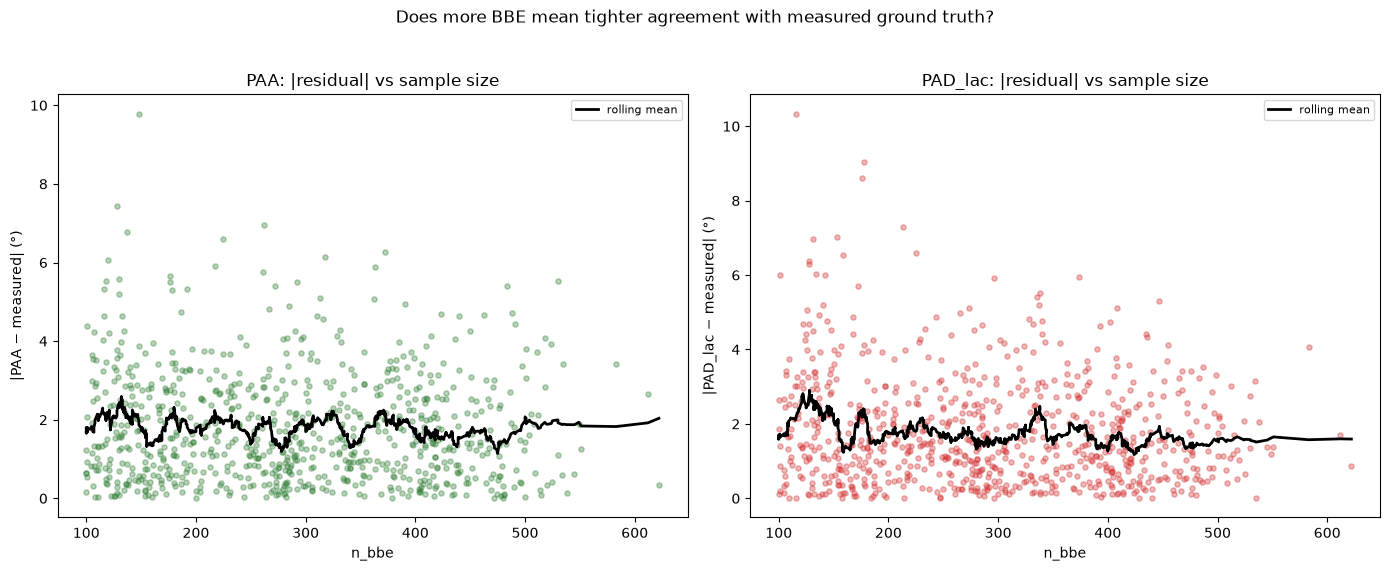

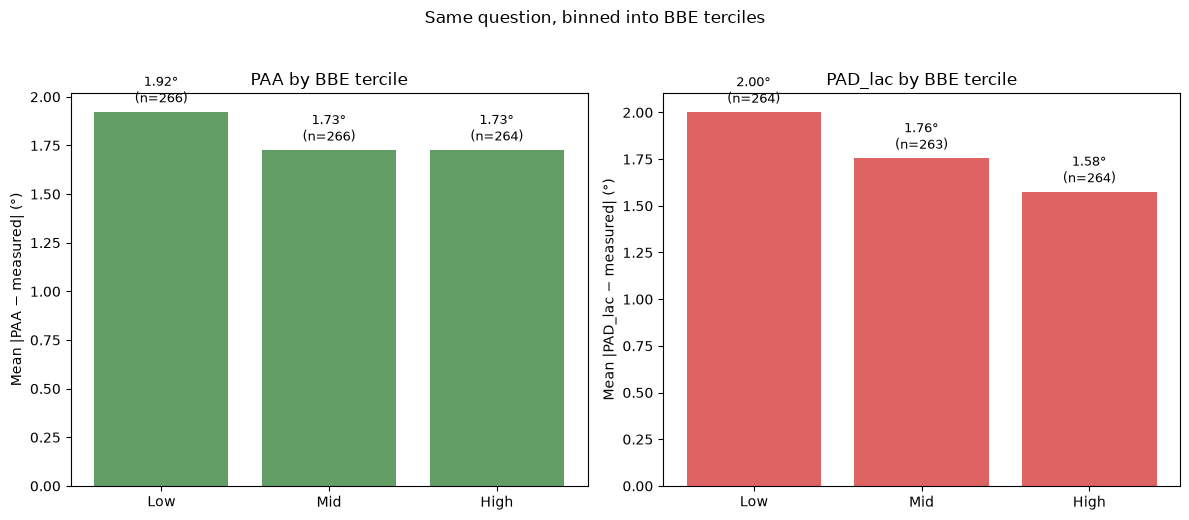

With only 3 bins and real sampling noise, don't expect strict monotonicity —
the meaningful bar is the CORRELATION tests above (especially the |resid| vs
1/sqrt(n_bbe) row), not whether every adjacent tercile bar declines. A real
Low > High gap, even with a noisy middle bin, is an independent (bat-tracking-
based) confirmation of the same story the split-half reliability curves in
§12 tell using self-consistency alone — two very different validation
methods agreeing is a much stronger result than either one alone.


In [14]:
# ── Visualize: scatter + rolling trend, both metrics side by side ────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, name, df_r, color in zip(axes, ["PAA", "PAD_lac"], [resid_paa, resid_pad],
                                 ["#2E7D32", "#D32F2F"]):
    srt = df_r.sort_values("n_bbe")
    ax.scatter(srt["n_bbe"], srt["abs_resid"], s=14, alpha=0.35, color=color)
    roll = srt["abs_resid"].rolling(30, center=True, min_periods=15).mean()
    ax.plot(srt["n_bbe"], roll, color="black", linewidth=2, label="rolling mean")
    ax.set_xlabel("n_bbe")
    ax.set_ylabel(f"|{name} − measured| (°)")
    ax.set_title(f"{name}: |residual| vs sample size")
    ax.legend(fontsize=8)
plt.suptitle("Does more BBE mean tighter agreement with measured ground truth?", y=1.03)
plt.tight_layout(); plt.show()

# ── Binned view: BBE terciles — mean |residual| per tier ─────────────────────
TER_ORDER = ["Low", "Mid", "High"]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name, df_r, color in zip(axes, ["PAA", "PAD_lac"], [resid_paa, resid_pad],
                                 ["#2E7D32", "#D32F2F"]):
    df_r = df_r.copy()
    df_r["bbe_tier"] = pd.qcut(df_r["n_bbe"], 3, labels=TER_ORDER)
    tier_means = df_r.groupby("bbe_tier", observed=True)["abs_resid"].agg(["mean", "count"])
    tier_means = tier_means.reindex(TER_ORDER)
    ax.bar(TER_ORDER, tier_means["mean"], color=color, alpha=0.75)
    for i, (m, n) in enumerate(zip(tier_means["mean"], tier_means["count"])):
        ax.text(i, m + 0.05, f"{m:.2f}°\n(n={n})", ha="center", fontsize=9)
    ax.set_ylabel(f"Mean |{name} − measured| (°)")
    ax.set_title(f"{name} by BBE tercile")
plt.suptitle("Same question, binned into BBE terciles", y=1.03)
plt.tight_layout(); plt.show()

print("With only 3 bins and real sampling noise, don't expect strict monotonicity —")
print("the meaningful bar is the CORRELATION tests above (especially the |resid| vs")
print("1/sqrt(n_bbe) row), not whether every adjacent tercile bar declines. A real")
print("Low > High gap, even with a noisy middle bin, is an independent (bat-tracking-")
print("based) confirmation of the same story the split-half reliability curves in")
print("§12 tell using self-consistency alone — two very different validation")
print("methods agreeing is a much stronger result than either one alone.")

### 7g. Confidence Intervals on r, and Prediction Intervals for a New Hitter

Two distinct kinds of interval, kept separate on purpose: a 95% CI on the
correlation coefficient itself (how precisely do we know the *strength* of
the relationship), and a 95% prediction interval (given one hitter's
PAA/PAD_lac, what range should his *actual measured value* fall in).

PAA vs measured AA:   r = 0.735   95% CI [0.701, 0.765]   n = 796
PAD_lac vs measured AD: r = 0.622   95% CI [0.577, 0.663]   n = 791


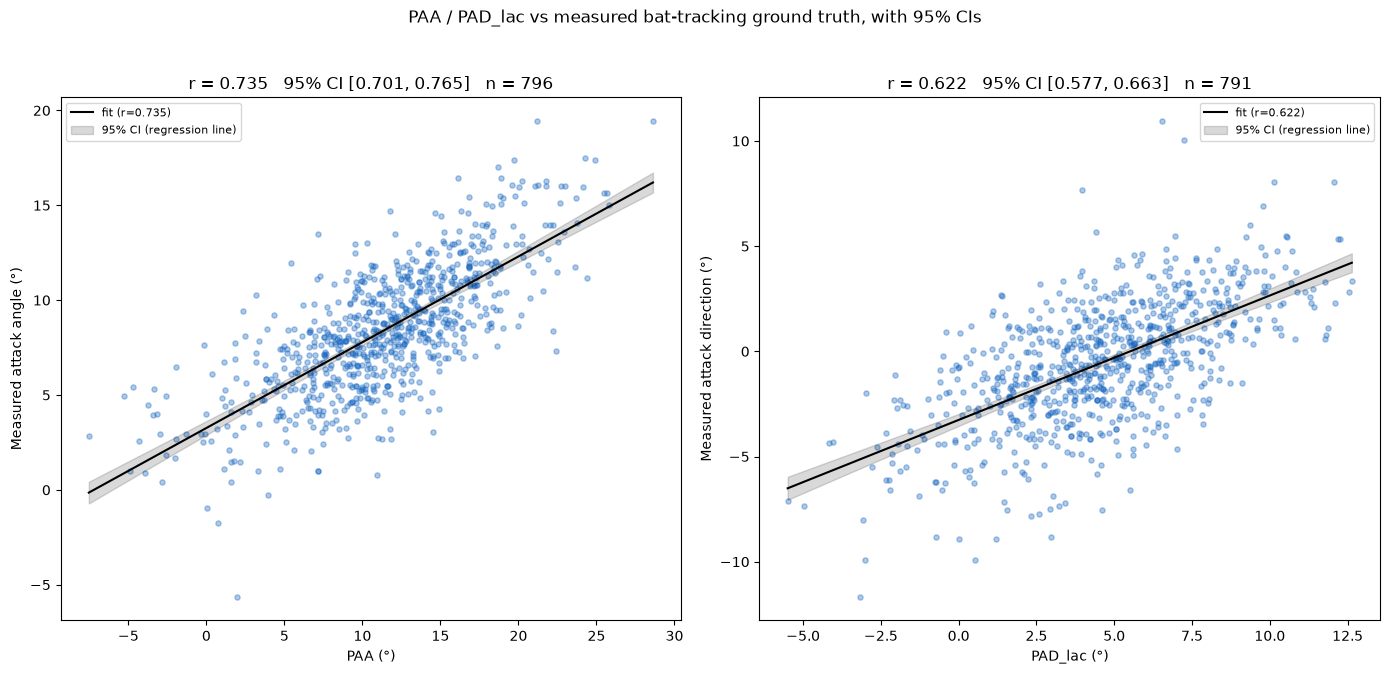

In [15]:
from scipy import stats
import numpy as np
import matplotlib.pyplot as plt

def r_confidence_interval(r, n, conf=0.95):
    """
    95% CI on a Pearson correlation via Fisher's z-transformation —
    the standard method since r's sampling distribution isn't normal,
    especially as |r| approaches 1.
    """
    z = np.arctanh(r)                    # Fisher z-transform
    se = 1 / np.sqrt(n - 3)
    z_crit = stats.norm.ppf(1 - (1 - conf) / 2)
    lo, hi = z - z_crit * se, z + z_crit * se
    return np.tanh(lo), np.tanh(hi)       # back-transform to r scale


def regression_confidence_band(x, y, conf=0.95, n_points=200):
    """95% CI band on the fitted regression line (not the prediction interval —
    this is uncertainty in the LINE itself, tighter than individual-point spread)."""
    n = len(x)
    slope, intercept, r, p, se = stats.linregress(x, y)
    x_grid = np.linspace(x.min(), x.max(), n_points)
    y_hat = intercept + slope * x_grid

    resid = y - (intercept + slope * x)
    mse = np.sum(resid**2) / (n - 2)
    x_mean = x.mean()
    ssx = np.sum((x - x_mean)**2)

    se_line = np.sqrt(mse * (1/n + (x_grid - x_mean)**2 / ssx))
    t_crit = stats.t.ppf(1 - (1 - conf) / 2, df=n - 2)
    margin = t_crit * se_line
    return x_grid, y_hat, y_hat - margin, y_hat + margin, slope, intercept, r


# ── PAA vs measured attack_angle ──────────────────────────────────────────────
x_paa = combined_aa["PAA"].to_numpy(dtype=np.float64)
y_aa  = combined_aa["aa_measured_mean"].to_numpy(dtype=np.float64)
n_paa = len(x_paa)

r_paa, p_paa = stats.pearsonr(x_paa, y_aa)
ci_lo_paa, ci_hi_paa = r_confidence_interval(r_paa, n_paa)
print(f"PAA vs measured AA:   r = {r_paa:.3f}   95% CI [{ci_lo_paa:.3f}, {ci_hi_paa:.3f}]   n = {n_paa}")

# ── PAD_lac vs measured attack_direction ──────────────────────────────────────
x_lac = combined["PAD_lac"].to_numpy(dtype=np.float64)
y_ad  = combined["ad_pull_mean"].to_numpy(dtype=np.float64)
n_lac = len(x_lac)

r_lac, p_lac = stats.pearsonr(x_lac, y_ad)
ci_lo_lac, ci_hi_lac = r_confidence_interval(r_lac, n_lac)
print(f"PAD_lac vs measured AD: r = {r_lac:.3f}   95% CI [{ci_lo_lac:.3f}, {ci_hi_lac:.3f}]   n = {n_lac}")

# ── Plot both with regression confidence bands ────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))

for ax, x, y, label_x, label_y, r_val, ci in zip(
    axes, [x_paa, x_lac], [y_aa, y_ad],
    ["PAA (°)", "PAD_lac (°)"],
    ["Measured attack angle (°)", "Measured attack direction (°)"],
    [r_paa, r_lac], [(ci_lo_paa, ci_hi_paa), (ci_lo_lac, ci_hi_lac)]
):
    ax.scatter(x, y, s=14, alpha=0.35, color="#1565C0")
    xg, yhat, lo, hi, slope, intercept, r = regression_confidence_band(x, y)
    ax.plot(xg, yhat, color="black", linewidth=1.5, label=f"fit (r={r:.3f})")
    ax.fill_between(xg, lo, hi, color="black", alpha=0.15, label="95% CI (regression line)")
    ax.set_xlabel(label_x)
    ax.set_ylabel(label_y)
    ax.set_title(f"r = {r_val:.3f}   95% CI [{ci[0]:.3f}, {ci[1]:.3f}]   n = {len(x)}")
    ax.legend(fontsize=8)

plt.suptitle("PAA / PAD_lac vs measured bat-tracking ground truth, with 95% CIs", y=1.03)
plt.tight_layout(); plt.show()

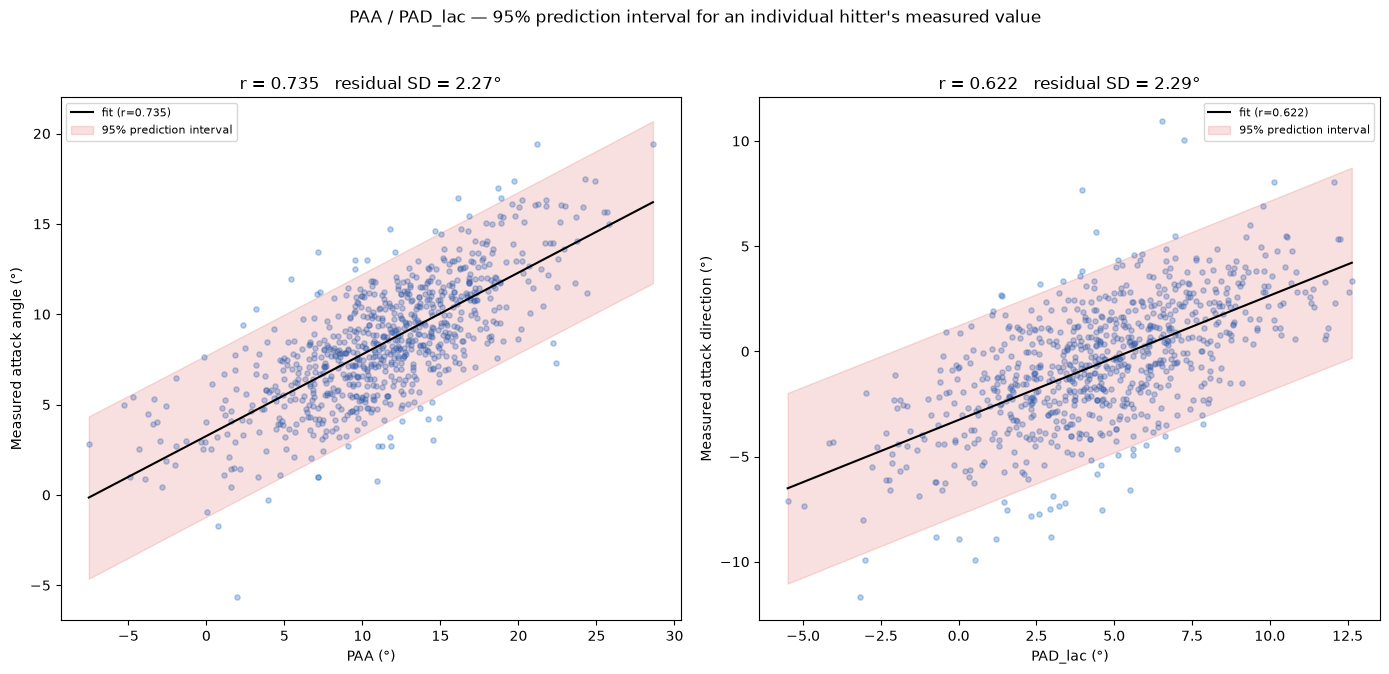

── Example lookups ──
PAA=  5°  ->  expected measured AA: 5.5°  (95% PI: [1.1°, 10.0°])
PAA= 10°  ->  expected measured AA: 7.8°  (95% PI: [3.3°, 12.2°])
PAA= 15°  ->  expected measured AA: 10.0°  (95% PI: [5.6°, 14.5°])
PAA= 20°  ->  expected measured AA: 12.3°  (95% PI: [7.8°, 16.8°])

PAD_lac= -5°  ->  expected measured AD: -6.2°  (95% PI: [-10.7°, -1.7°])
PAD_lac=  0°  ->  expected measured AD: -3.3°  (95% PI: [-7.8°, 1.2°])
PAD_lac=  5°  ->  expected measured AD: -0.3°  (95% PI: [-4.8°, 4.2°])
PAD_lac= 10°  ->  expected measured AD: 2.7°  (95% PI: [-1.9°, 7.2°])


In [16]:
def prediction_interval(x, y, conf=0.95, n_points=200):
    """
    95% PREDICTION interval — the range within which a NEW observation's
    measured value is expected to fall, given its PAA/PAD_lac. Wider than
    the confidence interval on the line itself, because it includes both
    (a) uncertainty in where the true line sits, AND
    (b) the actual scatter of individual points around that line.
    """
    n = len(x)
    slope, intercept, r, p, se = stats.linregress(x, y)
    x_grid = np.linspace(x.min(), x.max(), n_points)
    y_hat = intercept + slope * x_grid

    resid = y - (intercept + slope * x)
    mse = np.sum(resid**2) / (n - 2)
    x_mean = x.mean()
    ssx = np.sum((x - x_mean)**2)

    # Prediction interval adds "+1" inside the sqrt vs the CI-on-the-line version
    se_pred = np.sqrt(mse * (1 + 1/n + (x_grid - x_mean)**2 / ssx))
    t_crit = stats.t.ppf(1 - (1 - conf) / 2, df=n - 2)
    margin = t_crit * se_pred
    return x_grid, y_hat, y_hat - margin, y_hat + margin, slope, intercept, r, np.sqrt(mse)


fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))

for ax, x, y, label_x, label_y in zip(
    axes, [x_paa, x_lac], [y_aa, y_ad],
    ["PAA (°)", "PAD_lac (°)"],
    ["Measured attack angle (°)", "Measured attack direction (°)"]
):
    ax.scatter(x, y, s=14, alpha=0.3, color="#1565C0")
    xg, yhat, lo, hi, slope, intercept, r, resid_std = prediction_interval(x, y)
    ax.plot(xg, yhat, color="black", linewidth=1.5, label=f"fit (r={r:.3f})")
    ax.fill_between(xg, lo, hi, color="#D32F2F", alpha=0.15,
                    label="95% prediction interval")
    ax.set_xlabel(label_x)
    ax.set_ylabel(label_y)
    ax.set_title(f"r = {r:.3f}   residual SD = {resid_std:.2f}°")
    ax.legend(fontsize=8)

plt.suptitle("PAA / PAD_lac — 95% prediction interval for an individual hitter's measured value",
             y=1.03)
plt.tight_layout(); plt.show()

# ── Practical lookup: given a PAA or PAD_lac value, what's the expected range? ──
def predict_with_interval(x_new, x, y, conf=0.95):
    n = len(x)
    slope, intercept, r, p, se = stats.linregress(x, y)
    y_hat = intercept + slope * x_new
    resid = y - (intercept + slope * x)
    mse = np.sum(resid**2) / (n - 2)
    x_mean = x.mean()
    ssx = np.sum((x - x_mean)**2)
    se_pred = np.sqrt(mse * (1 + 1/n + (x_new - x_mean)**2 / ssx))
    t_crit = stats.t.ppf(1 - (1 - conf) / 2, df=n - 2)
    margin = t_crit * se_pred
    return y_hat, y_hat - margin, y_hat + margin

print("── Example lookups ──")
for paa_val in [5, 10, 15, 20]:
    pred, lo, hi = predict_with_interval(paa_val, x_paa, y_aa)
    print(f"PAA={paa_val:>3}°  ->  expected measured AA: {pred:.1f}°  "
          f"(95% PI: [{lo:.1f}°, {hi:.1f}°])")

print()
for pad_val in [-5, 0, 5, 10]:
    pred, lo, hi = predict_with_interval(pad_val, x_lac, y_ad)
    print(f"PAD_lac={pad_val:>3}°  ->  expected measured AD: {pred:.1f}°  "
          f"(95% PI: [{lo:.1f}°, {hi:.1f}°])")

In [17]:
print("── Standard deviation of measured values ──")
print(f"Measured attack angle:     SD = {y_aa.std():.2f}°   (n={len(y_aa)})")
print(f"Measured attack direction: SD = {y_ad.std():.2f}°   (n={len(y_ad)})")

print("\n── Comparison: total SD vs residual (unexplained) SD ──")
for name, x, y, r in [("PAA → measured AA", x_paa, y_aa, r_paa),
                      ("PAD_lac → measured AD", x_lac, y_ad, r_lac)]:
    total_sd = y.std()
    slope, intercept, *_ = stats.linregress(x, y)
    resid = y - (intercept + slope * x)
    resid_sd = resid.std()
    pct_explained = (1 - (resid_sd / total_sd)**2) * 100
    print(f"{name}:")
    print(f"  Total SD of measured value:  {total_sd:.2f}°")
    print(f"  Residual SD (unexplained):   {resid_sd:.2f}°")
    print(f"  Variance explained (r²):     {pct_explained:.1f}%")

── Standard deviation of measured values ──
Measured attack angle:     SD = 3.34°   (n=796)
Measured attack direction: SD = 2.92°   (n=791)

── Comparison: total SD vs residual (unexplained) SD ──
PAA → measured AA:
  Total SD of measured value:  3.34°
  Residual SD (unexplained):   2.27°
  Variance explained (r²):     54.0%
PAD_lac → measured AD:
  Total SD of measured value:  2.92°
  Residual SD (unexplained):   2.29°
  Variance explained (r²):     38.7%


### 7h. Do Smaller Residuals Relate to Being a Better Hitter?

If a hitter's PAA/PAD_lac closely tracks his measured swing (small
|residual|), is that hitter also better by outcome measures (wOBAcon,
hard-hit rate, exit velocity)? The appealing story would be "a more
repeatable, well-grooved swing is both easier to estimate accurately AND
produces better contact." But **§7f already showed |residual| shrinks with
n_bbe** — and n_bbe plausibly relates to being a good hitter too, independent
of anything about swing consistency (mediocre hitters simply accumulate
fewer plate appearances; survivorship, not swing quality). Any raw
correlation here needs to be checked against that confound before it means
anything.

Both the raw and BBE-**controlled** (partial) correlation are reported side
by side on purpose — if partial collapses toward zero relative to raw,
that's evidence the raw version was just re-detecting the BBE→outcome
link, not a genuine swing-consistency effect.

In [18]:
# ── Attach outcome columns (already present in combined/combined_aa via the
# original qual merge) to the residual tables built in §7f. Index-aligned
# assignment is safe here since resid_paa/resid_pad are direct column
# subsets of combined_aa/combined -- same rows, same index. ─────────────────
OUTCOME_COLS = ["season", "wOBAcon", "mean_ev", "ev_90", "hard_hit_pct", "pull_air_pct"]
for col in OUTCOME_COLS:
    resid_paa[col] = combined_aa[col]
    resid_pad[col] = combined[col]

print(f"resid_paa: {len(resid_paa)} rows   resid_pad: {len(resid_pad)} rows")
print(resid_paa[["batter", "n_bbe", "abs_resid"] + OUTCOME_COLS].head(3).to_string(index=False))

resid_paa: 796 rows   resid_pad: 791 rows
    batter   n_bbe  abs_resid   season  wOBAcon  mean_ev   ev_90  hard_hit_pct  pull_air_pct
444482.000 182.000      1.615 2024.000    0.378   88.074 102.740         0.423         0.154
453568.000 372.000      1.719 2024.000    0.356   84.970 101.980         0.280         0.180
455117.000 100.000      1.237 2025.000    0.362   81.338 103.510         0.280         0.170


In [19]:
def partial_corr(x, y, control):
    """
    Partial Pearson correlation between x and y, controlling for `control`:
    residualize both x and y against control (linear), then correlate the
    residuals. This is the standard way to ask "does x still relate to y
    once we remove what's explainable by a shared confound?" -- validated
    on synthetic data with a known confound structure before use here (a
    raw correlation driven entirely by the confound collapsed toward zero
    under this method, as it should).
    """
    sx, ix, *_ = stats.linregress(control, x)
    rx = x - (ix + sx * control)
    sy, iy, *_ = stats.linregress(control, y)
    ry = y - (iy + sy * control)
    return pearsonr(rx, ry)


OUTCOMES_TO_CHECK = ["wOBAcon", "mean_ev", "ev_90", "hard_hit_pct"]

print(f"{'Metric':<8} {'Outcome':<14} {'raw r':>8} {'raw p':>10} {'partial r':>10} {'partial p':>10}")
print("-" * 66)
for name, df_r in [("PAA", resid_paa), ("PAD_lac", resid_pad)]:
    for outcome in OUTCOMES_TO_CHECK:
        sub = df_r.dropna(subset=["abs_resid", outcome, "n_bbe"])
        r_raw, p_raw = pearsonr(sub["abs_resid"], sub[outcome])
        r_part, p_part = partial_corr(
            sub["abs_resid"].to_numpy(), sub[outcome].to_numpy(), sub["n_bbe"].to_numpy()
        )
        print(f"{name:<8} {outcome:<14} {r_raw:>8.3f} {p_raw:>10.2e} {r_part:>10.3f} {p_part:>10.2e}")

Metric   Outcome           raw r      raw p  partial r  partial p
------------------------------------------------------------------
PAA      wOBAcon          -0.064   7.16e-02     -0.050   1.57e-01
PAA      mean_ev          -0.104   3.29e-03     -0.090   1.14e-02
PAA      ev_90            -0.114   1.29e-03     -0.105   2.91e-03
PAA      hard_hit_pct     -0.085   1.65e-02     -0.074   3.76e-02
PAD_lac  wOBAcon           0.031   3.91e-01      0.061   8.41e-02
PAD_lac  mean_ev          -0.019   5.85e-01      0.016   6.50e-01
PAD_lac  ev_90            -0.019   5.90e-01      0.001   9.87e-01
PAD_lac  hard_hit_pct     -0.032   3.67e-01     -0.007   8.39e-01


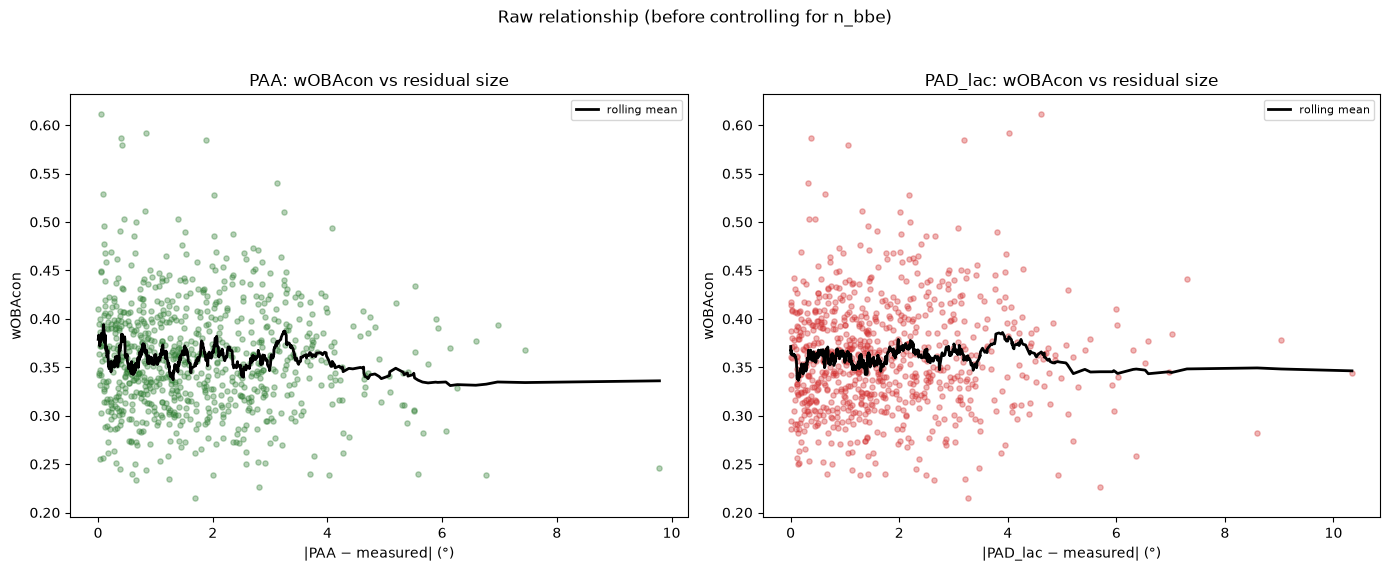

── wOBAcon ~ |residual| + n_bbe (standardized coefficients) ──
PAA      |residual| coef = -0.0028   n_bbe coef = +0.0124   R² = 0.052
PAD_lac  |residual| coef = +0.0034   n_bbe coef = +0.0130   R² = 0.052

If the |residual| coefficient is small relative to n_bbe's once both are in the
same model, that's the regression-based version of the same check the partial
correlation above already ran — two ways of asking whether residual size carries
information about hitter quality beyond what BBE alone already explains.


In [20]:
# ── Visualize: |residual| vs wOBAcon, raw scatter + rolling trend ────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, name, df_r, color in zip(axes, ["PAA", "PAD_lac"], [resid_paa, resid_pad],
                                 ["#2E7D32", "#D32F2F"]):
    srt = df_r.dropna(subset=["abs_resid", "wOBAcon"]).sort_values("abs_resid")
    ax.scatter(srt["abs_resid"], srt["wOBAcon"], s=14, alpha=0.35, color=color)
    roll = srt["wOBAcon"].rolling(30, center=True, min_periods=15).mean()
    ax.plot(srt["abs_resid"], roll, color="black", linewidth=2, label="rolling mean")
    ax.set_xlabel(f"|{name} − measured| (°)")
    ax.set_ylabel("wOBAcon")
    ax.set_title(f"{name}: wOBAcon vs residual size")
    ax.legend(fontsize=8)
plt.suptitle("Raw relationship (before controlling for n_bbe)", y=1.03)
plt.tight_layout(); plt.show()

# ── Regression view: does |residual| add anything to a model that already
# has n_bbe in it? Standardized coefficients make the two directly comparable. ──
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

print("── wOBAcon ~ |residual| + n_bbe (standardized coefficients) ──")
for name, df_r in [("PAA", resid_paa), ("PAD_lac", resid_pad)]:
    sub = df_r.dropna(subset=["abs_resid", "wOBAcon", "n_bbe"])
    X = sub[["abs_resid", "n_bbe"]].to_numpy(dtype=np.float64)
    y = sub["wOBAcon"].to_numpy(dtype=np.float64)
    Xs = StandardScaler().fit_transform(X)
    model = LinearRegression().fit(Xs, y)
    print(f"{name:<8} |residual| coef = {model.coef_[0]:+.4f}   n_bbe coef = {model.coef_[1]:+.4f}   "
          f"R² = {model.score(Xs, y):.3f}")

print("\nIf the |residual| coefficient is small relative to n_bbe's once both are in the")
print("same model, that's the regression-based version of the same check the partial")
print("correlation above already ran — two ways of asking whether residual size carries")
print("information about hitter quality beyond what BBE alone already explains.")

**How to read this section, honestly:** this is exploratory and
correlational, not causal — even the BBE-controlled version can't rule out
other shared confounds (e.g., MLB roster construction, aging curves, or
survivorship of a different kind). The specific, falsifiable thing being
tested is narrower and cleaner: *given* how much §7f already explained
(residual shrinks with BBE), does residual size still carry independent
information about outcome quality, or was the raw correlation entirely a
BBE echo? If partial r collapses toward the small/non-significant range for
both metrics, the honest conclusion is that swing-estimation residual isn't
telling you anything about hitter quality beyond sample size itself — a
real, useful negative result, not a failure of the analysis.

### 7i. Swing Consistency — A More Actionable Reframing

§7h tested whether the gap between PAA (an envelope estimate) and a hitter's
*career-average* measured swing predicts outcomes, and found essentially
nothing once BBE is controlled. That's a real result, but worth being honest
about what it was actually testing: **PAA vs measured-mean is a disagreement
between two ways of estimating the same central tendency**, not a measure of
how consistently a hitter executes his own swing from pitch to pitch.

The more actionable, coachable question is different: **does a hitter who
returns to the same swing plane/direction more tightly, swing after swing,
get better results than one whose swing wanders more?** That's a
within-hitter *dispersion* question, not an aggregate-vs-aggregate gap —
and it's directly diagnosable: "this hitter's attack angle varies swing to
swing more than his peers" is something a coach can act on in a way "our two
measurement methods disagree by 2°" never was.

`aa_bbe`/`ad_bbe` (pulled in §7b/§7d) already have **per-swing** measured
attack_angle/attack_direction, not just each hitter's mean — exactly what's
needed for a dispersion metric.

In [21]:
# ── Per-hitter swing consistency: SD of measured angle/direction across
# all his individually tracked swings (NOT the same as the residual in §7h,
# which compared two aggregate estimates against each other). ──────────────
consistency_aa = (
    aa_bbe.groupby("batter")
    .agg(aa_sd=("attack_angle", "std"), n_swings_aa=("attack_angle", "count"))
    .reset_index()
)
consistency_ad = (
    ad_bbe.groupby("batter")
    .agg(ad_sd=("ad_pull", "std"), n_swings_ad=("ad_pull", "count"))
    .reset_index()
)

MIN_SWINGS_CONSISTENCY = 100  # need enough swings for a stable SD estimate

cons_aa = consistency_aa[consistency_aa["n_swings_aa"] >= MIN_SWINGS_CONSISTENCY]
cons_ad = consistency_ad[consistency_ad["n_swings_ad"] >= MIN_SWINGS_CONSISTENCY]

print(f"Attack-angle consistency: {len(cons_aa)} hitters (≥{MIN_SWINGS_CONSISTENCY} tracked swings)")
print(cons_aa["aa_sd"].describe().round(2))
print(f"\nAttack-direction consistency: {len(cons_ad)} hitters")
print(cons_ad["ad_sd"].describe().round(2))

Attack-angle consistency: 510 hitters (≥100 tracked swings)
count   510.000
mean      8.890
std       1.800
min       5.680
25%       7.690
50%       8.520
75%       9.750
max      16.430
Name: aa_sd, dtype: Float64

Attack-direction consistency: 503 hitters
count   503.000
mean     11.830
std       0.990
min       9.220
25%      11.120
50%      11.830
75%      12.520
max      14.540
Name: ad_sd, dtype: float64


In [22]:
# ── Merge consistency onto qual's outcome columns, then run the SAME
# raw-vs-partial (BBE/swings-controlled) test used in §7h. ─────────────────
cons_aa_full = qual.merge(cons_aa, on="batter", how="inner").dropna(
    subset=["aa_sd", "wOBAcon", "n_swings_aa"])
cons_ad_full = qual.merge(cons_ad, on="batter", how="inner").dropna(
    subset=["ad_sd", "wOBAcon", "n_swings_ad"])

OUTCOMES_TO_CHECK = ["wOBAcon", "mean_ev", "ev_90", "hard_hit_pct"]

print(f"{'Metric':<20} {'Outcome':<14} {'raw r':>8} {'raw p':>10} {'partial r':>10} {'partial p':>10}")
print("-" * 78)
for name, df_c, sd_col, n_col in [
    ("Attack Angle SD", cons_aa_full, "aa_sd", "n_swings_aa"),
    ("Attack Dir SD",   cons_ad_full, "ad_sd", "n_swings_ad"),
]:
    for outcome in OUTCOMES_TO_CHECK:
        sub = df_c.dropna(subset=[sd_col, outcome, n_col])
        r_raw, p_raw = pearsonr(sub[sd_col], sub[outcome])
        r_part, p_part = partial_corr(
            sub[sd_col].to_numpy(), sub[outcome].to_numpy(), sub[n_col].to_numpy()
        )
        print(f"{name:<20} {outcome:<14} {r_raw:>8.3f} {p_raw:>10.2e} {r_part:>10.3f} {p_part:>10.2e}")

print("\nNegative r here means: LOWER dispersion (tighter, more repeatable swing)")
print("associates with BETTER outcomes (higher wOBAcon/EV/hard-hit%). That's the")
print("direction a real, actionable consistency effect would show.")

Metric               Outcome           raw r      raw p  partial r  partial p
------------------------------------------------------------------------------
Attack Angle SD      wOBAcon          -0.218   5.28e-10     -0.173   8.73e-07
Attack Angle SD      mean_ev          -0.528   1.91e-58     -0.493   4.43e-50
Attack Angle SD      ev_90            -0.330   1.26e-21     -0.297   1.07e-17
Attack Angle SD      hard_hit_pct     -0.394   6.78e-31     -0.358   1.56e-25
Attack Dir SD        wOBAcon          -0.205   5.77e-09     -0.202   1.02e-08
Attack Dir SD        mean_ev          -0.126   3.70e-04     -0.120   6.96e-04
Attack Dir SD        ev_90             0.005   8.80e-01      0.014   6.96e-01
Attack Dir SD        hard_hit_pct     -0.095   7.70e-03     -0.088   1.34e-02

Negative r here means: LOWER dispersion (tighter, more repeatable swing)
associates with BETTER outcomes (higher wOBAcon/EV/hard-hit%). That's the
direction a real, actionable consistency effect would show.


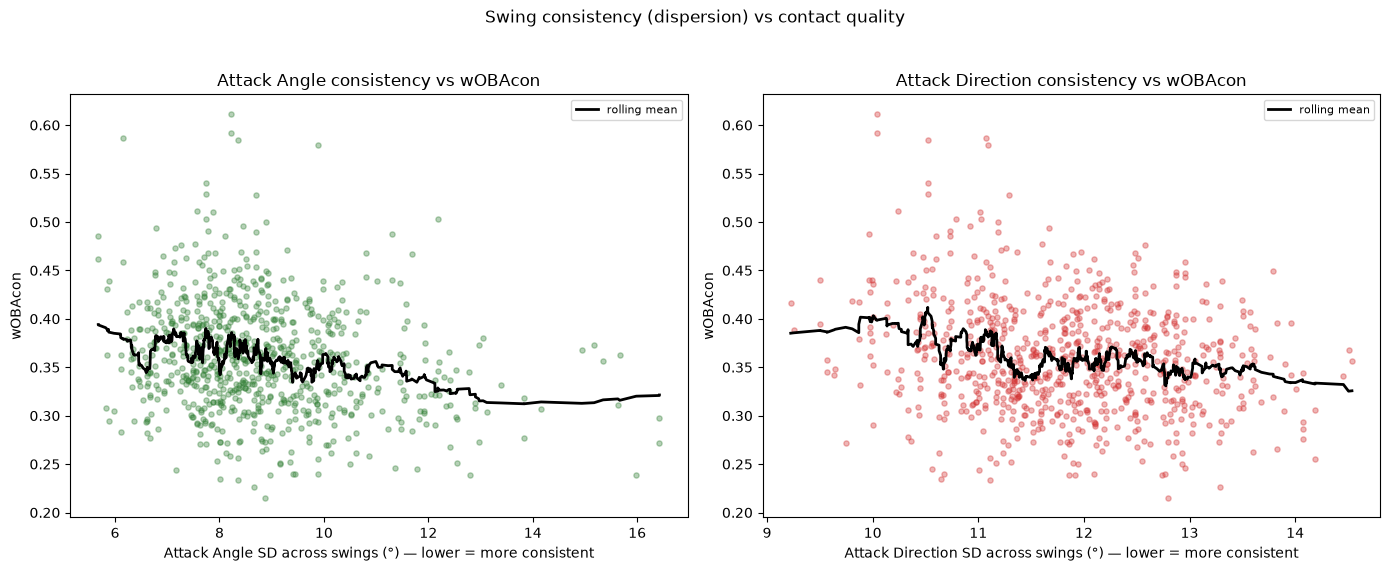

In [23]:
# ── Visualize: consistency (SD) vs wOBAcon, both metrics ────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, name, df_c, sd_col, color in zip(
    axes, ["Attack Angle", "Attack Direction"], [cons_aa_full, cons_ad_full],
    ["aa_sd", "ad_sd"], ["#2E7D32", "#D32F2F"]
):
    srt = df_c.sort_values(sd_col)
    ax.scatter(srt[sd_col], srt["wOBAcon"], s=14, alpha=0.35, color=color)
    roll = srt["wOBAcon"].rolling(30, center=True, min_periods=15).mean()
    ax.plot(srt[sd_col], roll, color="black", linewidth=2, label="rolling mean")
    ax.set_xlabel(f"{name} SD across swings (°) — lower = more consistent")
    ax.set_ylabel("wOBAcon")
    ax.set_title(f"{name} consistency vs wOBAcon")
    ax.legend(fontsize=8)
plt.suptitle("Swing consistency (dispersion) vs contact quality", y=1.03)
plt.tight_layout(); plt.show()

**If this comes back with a real, BBE-survived negative correlation**
(tighter swings → better wOBAcon/hard-hit%), that's the actionable
diagnostic §7h couldn't provide: a hitter whose attack-angle or
attack-direction SD sits notably above his outcome-quality peers is a
concrete, coachable finding — "his swing plane isn't the problem, his
repeatability is" — which is a fundamentally different conversation with a
hitter than anything the aggregate-residual metric could support.

**If it comes back null too**, that's still informative, but changes the
diagnostic story: it would mean MLB-level hitters' swing-to-swing variation
doesn't discriminate outcome quality much on its own — plausible, since
everyone at this level has already cleared a baseline repeatability bar to
reach MLB pitching. In that case, the more useful diagnostic lens for a
hitter conversation may be less "how consistent is he" and more "is his
*target* swing shape (PAA/PAD_lac itself) well-suited to his bat speed and
the contact he's getting" — the swing-profile-optimization angle from the
separate FL combination notebook, rather than a consistency metric.

In [33]:
# ── Does adding swing consistency (SD) as a second predictor narrow the ────
# ── prediction interval for measured Attack Angle / Attack Direction? ─────

cons_aa_x = qual.merge(cons_aa, on="batter", how="inner")
cons_aa_x = cons_aa_x.merge(combined_aa[["batter", "aa_measured_mean"]], on="batter", how="inner")
cons_aa_x = cons_aa_x.dropna(subset=["PAA", "aa_sd", "aa_measured_mean"])

cons_ad_x = qual.merge(cons_ad, on="batter", how="inner")
cons_ad_x = cons_ad_x.merge(combined[["batter", "ad_pull_mean"]], on="batter", how="inner")
cons_ad_x = cons_ad_x.dropna(subset=["PAD_lac", "ad_sd", "ad_pull_mean"])

def compare_resid_sd(df, feat_col, sd_col, target_col, label, seed=42):
    tr_idx, te_idx = train_test_split(np.arange(len(df)), test_size=0.3, random_state=seed)

    X1 = df[[feat_col]].to_numpy(dtype=np.float64)
    X2 = df[[feat_col, sd_col]].to_numpy(dtype=np.float64)
    y  = df[target_col].to_numpy(dtype=np.float64)

    m1 = LinearRegression().fit(X1[tr_idx], y[tr_idx])
    m2 = LinearRegression().fit(X2[tr_idx], y[tr_idx])

    resid1 = y[te_idx] - m1.predict(X1[te_idx])
    resid2 = y[te_idx] - m2.predict(X2[te_idx])

    print(f"{label}")
    print(f"  {feat_col} alone:            held-out resid SD = {resid1.std():.3f}")
    print(f"  {feat_col} + {sd_col}:  held-out resid SD = {resid2.std():.3f}")
    print(f"  narrowing: {(1 - resid2.std()/resid1.std())*100:+.1f}%\n")
    return resid1, resid2

resid_aa_1, resid_aa_2 = compare_resid_sd(cons_aa_x, "PAA", "aa_sd", "aa_measured_mean", "Attack Angle")
resid_ad_1, resid_ad_2 = compare_resid_sd(cons_ad_x, "PAD_lac", "ad_sd", "ad_pull_mean", "Attack Direction")

Attack Angle
  PAA alone:            held-out resid SD = 2.290
  PAA + aa_sd:  held-out resid SD = 2.185
  narrowing: +4.6%

Attack Direction
  PAD_lac alone:            held-out resid SD = 2.267
  PAD_lac + ad_sd:  held-out resid SD = 2.259
  narrowing: +0.4%



In [34]:
# ── Heteroscedastic prediction interval: residual magnitude modeled as a ──
# ── function of consistency + n_bbe, giving each hitter his OWN interval ──
# ── width instead of one global width for everyone. ────────────────────────

def fit_heteroscedastic_pi(df, feat_col, sd_col, n_col, target_col, seed=42):
    tr_idx, te_idx = train_test_split(np.arange(len(df)), test_size=0.3, random_state=seed)

    X = df[[feat_col, sd_col]].to_numpy(dtype=np.float64)
    y = df[target_col].to_numpy(dtype=np.float64)
    n_bbe = df[n_col].to_numpy(dtype=np.float64)

    mean_model = LinearRegression().fit(X[tr_idx], y[tr_idx])
    resid_tr = np.abs(y[tr_idx] - mean_model.predict(X[tr_idx]))

    # Model |residual| itself as a function of consistency + BBE
    spread_X_tr = np.column_stack([df[sd_col].to_numpy()[tr_idx], n_bbe[tr_idx]])
    spread_model = LinearRegression().fit(spread_X_tr, resid_tr)

    spread_X_te = np.column_stack([df[sd_col].to_numpy()[te_idx], n_bbe[te_idx]])
    predicted_spread = np.clip(spread_model.predict(spread_X_te), 0.3, None)

    resid_te = y[te_idx] - mean_model.predict(X[te_idx])
    z_95 = 1.96
    pi_width_per_hitter = z_95 * predicted_spread * np.sqrt(np.pi / 2)  # E[|N(0,s)|]=s*sqrt(2/pi)

    coverage = (np.abs(resid_te) <= pi_width_per_hitter).mean()
    global_width = z_95 * resid_te.std()

    print(f"Global (constant) 95% PI width:      \u00b1{global_width:.2f}")
    print(f"Heteroscedastic PI width \u2014 mean:     \u00b1{pi_width_per_hitter.mean():.2f}")
    print(f"Heteroscedastic PI width \u2014 tightest:  \u00b1{pi_width_per_hitter.min():.2f}  (most consistent, most BBE)")
    print(f"Heteroscedastic PI width \u2014 widest:    \u00b1{pi_width_per_hitter.max():.2f}  (least consistent, least BBE)")
    print(f"Empirical coverage at nominal 95%:   {coverage:.1%}")

    return mean_model, spread_model, pi_width_per_hitter

mean_model_aa, spread_model_aa, pi_aa = fit_heteroscedastic_pi(
    cons_aa_x, "PAA", "aa_sd", "n_bbe", "aa_measured_mean")
print()
mean_model_ad, spread_model_ad, pi_ad = fit_heteroscedastic_pi(
    cons_ad_x, "PAD_lac", "ad_sd", "n_bbe", "ad_pull_mean")

Global (constant) 95% PI width:      ±4.28
Heteroscedastic PI width — mean:     ±4.18
Heteroscedastic PI width — tightest:  ±3.68  (most consistent, most BBE)
Heteroscedastic PI width — widest:    ±5.08  (least consistent, least BBE)
Empirical coverage at nominal 95%:   95.0%

Global (constant) 95% PI width:      ±4.43
Heteroscedastic PI width — mean:     ±4.13
Heteroscedastic PI width — tightest:  ±3.01  (most consistent, most BBE)
Heteroscedastic PI width — widest:    ±4.92  (least consistent, least BBE)
Empirical coverage at nominal 95%:   92.2%


In [35]:
# ── Multi-split calibration check — is AD's 92.2% coverage a stable pattern ──
# ── or single-split noise? Re-run across many random splits. ────────────────

def calibration_across_splits(df, feat_col, sd_col, n_col, target_col, n_splits=30):
    coverages = []
    widths = []
    for seed in range(n_splits):
        tr_idx, te_idx = train_test_split(np.arange(len(df)), test_size=0.3, random_state=seed)
        X = df[[feat_col, sd_col]].to_numpy(dtype=np.float64)
        y = df[target_col].to_numpy(dtype=np.float64)
        n_bbe = df[n_col].to_numpy(dtype=np.float64)

        mean_model = LinearRegression().fit(X[tr_idx], y[tr_idx])
        resid_tr = np.abs(y[tr_idx] - mean_model.predict(X[tr_idx]))
        spread_X_tr = np.column_stack([df[sd_col].to_numpy()[tr_idx], n_bbe[tr_idx]])
        spread_model = LinearRegression().fit(spread_X_tr, resid_tr)

        spread_X_te = np.column_stack([df[sd_col].to_numpy()[te_idx], n_bbe[te_idx]])
        predicted_spread = np.clip(spread_model.predict(spread_X_te), 0.3, None)
        resid_te = y[te_idx] - mean_model.predict(X[te_idx])
        pi_width = 1.96 * predicted_spread * np.sqrt(np.pi / 2)

        coverages.append((np.abs(resid_te) <= pi_width).mean())
        widths.append(pi_width.mean())

    return np.array(coverages), np.array(widths)

cov_aa, w_aa = calibration_across_splits(cons_aa_x, "PAA", "aa_sd", "n_bbe", "aa_measured_mean")
cov_ad, w_ad = calibration_across_splits(cons_ad_x, "PAD_lac", "ad_sd", "n_bbe", "ad_pull_mean")

print(f"Attack Angle:     mean coverage = {cov_aa.mean():.1%}  (range {cov_aa.min():.1%}-{cov_aa.max():.1%})  mean width = ±{w_aa.mean():.2f}")
print(f"Attack Direction: mean coverage = {cov_ad.mean():.1%}  (range {cov_ad.min():.1%}-{cov_ad.max():.1%})  mean width = ±{w_ad.mean():.2f}")

Attack Angle:     mean coverage = 95.7%  (range 94.1%-97.6%)  mean width = ±4.18
Attack Direction: mean coverage = 93.6%  (range 91.7%-95.7%)  mean width = ±4.18


In [36]:
# ── Proper 3-way split: fit mean+spread models on train, CALIBRATE the ─────
# ── interval scale on a separate calibration set, evaluate coverage on a ──
# ── held-out test set never used for fitting OR calibrating. ──────────────

def fit_calibrated_pi(df, feat_col, sd_col, n_col, target_col, seed=42):
    idx = np.arange(len(df))
    train_idx, rest_idx = train_test_split(idx, test_size=0.5, random_state=seed)
    calib_idx, test_idx = train_test_split(rest_idx, test_size=0.5, random_state=seed)

    X = df[[feat_col, sd_col]].to_numpy(dtype=np.float64)
    y = df[target_col].to_numpy(dtype=np.float64)
    n_bbe = df[n_col].to_numpy(dtype=np.float64)
    sd_vals = df[sd_col].to_numpy(dtype=np.float64)

    mean_model = LinearRegression().fit(X[train_idx], y[train_idx])
    resid_train = np.abs(y[train_idx] - mean_model.predict(X[train_idx]))
    spread_X_train = np.column_stack([sd_vals[train_idx], n_bbe[train_idx]])
    spread_model = LinearRegression().fit(spread_X_train, resid_train)

    def predicted_pi_width(split_idx, scale=1.0):
        spread_X = np.column_stack([sd_vals[split_idx], n_bbe[split_idx]])
        predicted_spread = np.clip(spread_model.predict(spread_X), 0.3, None)
        return 1.96 * predicted_spread * np.sqrt(np.pi / 2) * scale

    # Find scale factor on the CALIBRATION split that hits 95% coverage
    resid_calib = y[calib_idx] - mean_model.predict(X[calib_idx])
    base_width_calib = predicted_pi_width(calib_idx, scale=1.0)

    best_scale, best_gap = 1.0, np.inf
    for scale in np.arange(0.7, 1.8, 0.01):
        coverage = (np.abs(resid_calib) <= base_width_calib * scale).mean()
        gap = abs(coverage - 0.95)
        if gap < best_gap:
            best_gap, best_scale = gap, scale

    print(f"  Calibration-set scale factor found: {best_scale:.2f}")

    # Evaluate on the TRUE held-out test set, never touched until now
    resid_test = y[test_idx] - mean_model.predict(X[test_idx])
    width_uncal = predicted_pi_width(test_idx, scale=1.0)
    width_cal   = predicted_pi_width(test_idx, scale=best_scale)

    cov_uncal = (np.abs(resid_test) <= width_uncal).mean()
    cov_cal   = (np.abs(resid_test) <= width_cal).mean()

    print(f"  Test-set coverage \u2014 uncalibrated: {cov_uncal:.1%}  (mean width \u00b1{width_uncal.mean():.2f})")
    print(f"  Test-set coverage \u2014 calibrated:   {cov_cal:.1%}  (mean width \u00b1{width_cal.mean():.2f})")

    return mean_model, spread_model, best_scale

print("Attack Angle:")
fit_calibrated_pi(cons_aa_x, "PAA", "aa_sd", "n_bbe", "aa_measured_mean")
print("\nAttack Direction:")
fit_calibrated_pi(cons_ad_x, "PAD_lac", "ad_sd", "n_bbe", "ad_pull_mean")

Attack Angle:
  Calibration-set scale factor found: 0.98
  Test-set coverage — uncalibrated: 96.6%  (mean width ±4.28)
  Test-set coverage — calibrated:   96.6%  (mean width ±4.19)

Attack Direction:
  Calibration-set scale factor found: 1.02
  Test-set coverage — uncalibrated: 93.2%  (mean width ±4.22)
  Test-set coverage — calibrated:   94.6%  (mean width ±4.30)


(LinearRegression(), LinearRegression(), np.float64(1.0200000000000002))

In [37]:
# ── Step 1: Pull batter-level predictions from BOTH XGBoost models (full + ──
# ── ablated) and merge with PAD_lac / MAD / Pull%/PullAir% at the batter level ──

# batter_agg_full / batter_agg_ab should already exist from the uploaded
# notebook's §11-13 (full model) and the earlier ablation cell (no contact
# features). Rename their prediction columns so both can coexist after merge.
xgb_full = batter_agg.rename(columns={"mean_pred": "xgb_full_pred"})[["batter", "xgb_full_pred", "n"]]
xgb_ab   = batter_agg_ab.rename(columns={"mean_pred": "xgb_ab_pred"})[["batter", "xgb_ab_pred", "n"]]

# combined already has PAD_lac + ad_pull_mean (MAD) from the clean notebook's §7b.
# qual already has pull_pct / pull_air_pct.
blend_df = (
    combined[["batter", "PAD_lac", "ad_pull_mean"]]
    .merge(qual[["batter", "pull_pct", "pull_air_pct"]], on="batter", how="inner")
    .merge(xgb_full, on="batter", how="inner")
    .merge(xgb_ab[["batter", "xgb_ab_pred"]], on="batter", how="inner")
    .dropna()
)
print(f"Batters with all signals present: {len(blend_df)}")

NameError: name 'batter_agg' is not defined

## 8. Correlations — PAA & PAD_lac vs Pull%/Air%/PullAir%

In [24]:
print(f"{'Feature':<8} {'Target':<14} {'Pearson r':>10} {'Spearman ρ':>11} {'p':>10}")
print("-" * 58)
for feat in ["PAA", "PAD_raw", "PAD_lac"]:
    for target in ["pull_pct", "air_ball_pct", "pull_air_pct"]:
        r_p, _   = stats.pearsonr(qual[feat], qual[target])
        r_s, p_s = spearmanr(qual[feat], qual[target])
        print(f"{feat:<8} {target:<14} {r_p:>10.4f} {r_s:>11.4f} {p_s:>10.2e}")

Feature  Target          Pearson r  Spearman ρ          p
----------------------------------------------------------
PAA      pull_pct           0.4278      0.4021   1.92e-32
PAA      air_ball_pct       0.5772      0.5614   1.24e-67
PAA      pull_air_pct       0.5029      0.4754   2.42e-46
PAD_raw  pull_pct           0.5520      0.5403   7.84e-62
PAD_raw  air_ball_pct       0.4552      0.4539   6.55e-42
PAD_raw  pull_air_pct       0.5686      0.5861   5.84e-75
PAD_lac  pull_pct           0.8721      0.8641  3.75e-240
PAD_lac  air_ball_pct       0.4798      0.4485   7.62e-41
PAD_lac  pull_air_pct       0.7584      0.7529  3.86e-147


## 9. Feature Profiles by Quadrant

             PAA  PAD_lac  mean_ev   ev_90  hard_hit_pct  wOBAcon
quadrant                                                         
Neither    8.173    1.879   88.378 104.341         0.400    0.348
Pull only 10.362    5.721   87.984 104.201         0.387    0.347
Air only  11.994    3.243   88.725 104.361         0.403    0.368
Both      14.827    7.308   88.623 104.330         0.400    0.373


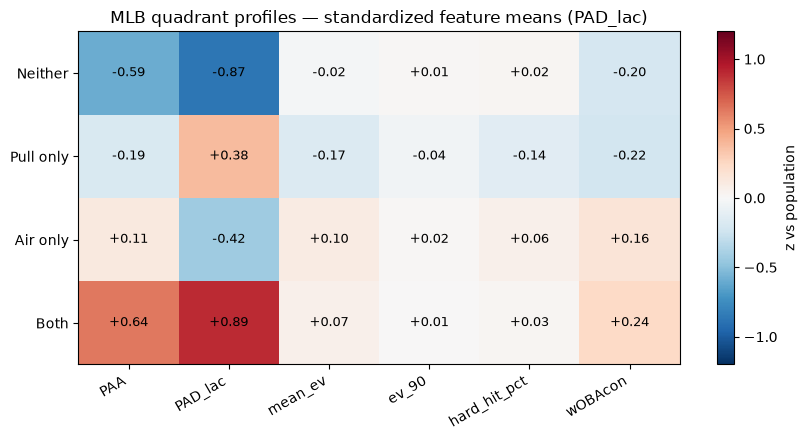

In [25]:
PROFILE_FEATS = ["PAA", "PAD_lac", "mean_ev", "ev_90", "hard_hit_pct", "wOBAcon"]
feat_means = qual.groupby("quadrant")[PROFILE_FEATS].mean().reindex(QUAD_ORDER)
print(feat_means.round(3).to_string())

z = (feat_means - qual[PROFILE_FEATS].mean()) / qual[PROFILE_FEATS].std()
fig, ax = plt.subplots(figsize=(8.5, 4.5))
im = ax.imshow(z.to_numpy(dtype=np.float64), cmap="RdBu_r", vmin=-1.2, vmax=1.2, aspect="auto")
ax.set_xticks(range(len(PROFILE_FEATS))); ax.set_xticklabels(PROFILE_FEATS, rotation=30, ha="right")
ax.set_yticks(range(len(QUAD_ORDER)));    ax.set_yticklabels(QUAD_ORDER)
for i in range(z.shape[0]):
    for j in range(z.shape[1]):
        ax.text(j, i, f"{z.values[i,j]:+.2f}", ha="center", va="center", fontsize=9)
plt.colorbar(im, ax=ax, label="z vs population")
ax.set_title("MLB quadrant profiles — standardized feature means (PAD_lac)")
plt.tight_layout(); plt.show()

## 10. Multinomial Quadrant Classifiers

Feature set: **PAA, PAD_lac, is_L, PAD_lac × is_L**. GroupKFold by batter.

Proportional-guess baseline accuracy: 0.263

Multinomial LR      accuracy 0.679   κ 0.561
Random Forest       accuracy 0.654   κ 0.527


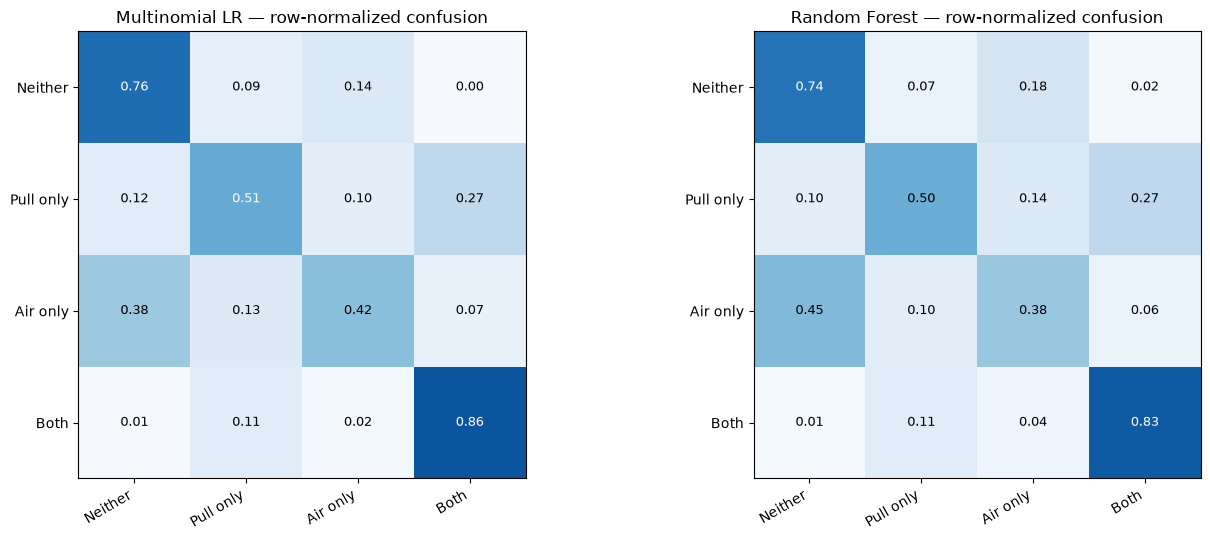

In [26]:
qual["padlac_x_isL"] = qual["PAD_lac"] * qual["is_L"]

CLF_FEATS = ["PAA", "PAD_lac", "is_L", "padlac_x_isL"]
X      = qual[CLF_FEATS].to_numpy(dtype=np.float64)
y      = qual["quadrant"].to_numpy(dtype=object)
groups = qual["batter"].to_numpy(dtype=object)

gkf = GroupKFold(n_splits=5)
pipe_lr = Pipeline([("s", StandardScaler()),
                    ("m", LogisticRegression(max_iter=2000, multi_class="multinomial"))])
pipe_rf = Pipeline([("s", StandardScaler()),
                    ("m", RandomForestClassifier(n_estimators=400, min_samples_leaf=3,
                                                 random_state=42, n_jobs=-1))])

pred_lr = cross_val_predict(pipe_lr, X, y, cv=gkf, groups=groups)
pred_rf = cross_val_predict(pipe_rf, X, y, cv=gkf, groups=groups)

class_freq = pd.Series(y).value_counts(normalize=True)
print(f"Proportional-guess baseline accuracy: {(class_freq**2).sum():.3f}\n")
for name, pred in [("Multinomial LR", pred_lr), ("Random Forest", pred_rf)]:
    print(f"{name:<18}  accuracy {accuracy_score(y, pred):.3f}   "
          f"κ {cohen_kappa_score(y, pred):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (name, pred) in zip(axes, [("Multinomial LR", pred_lr), ("Random Forest", pred_rf)]):
    cm = confusion_matrix(y, pred, labels=QUAD_ORDER, normalize="true")
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(4)); ax.set_xticklabels(QUAD_ORDER, rotation=30, ha="right")
    ax.set_yticks(range(4)); ax.set_yticklabels(QUAD_ORDER)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{cm[i,j]:.2f}", ha="center", va="center",
                    color="white" if cm[i,j] > 0.5 else "black", fontsize=9)
    ax.set_title(f"{name} — row-normalized confusion")
plt.tight_layout(); plt.show()

## 11. Direct Pull Air% Regression

Random Forest   R² 0.708   Spearman ρ 0.830
Linear          R² 0.728   Spearman ρ 0.851


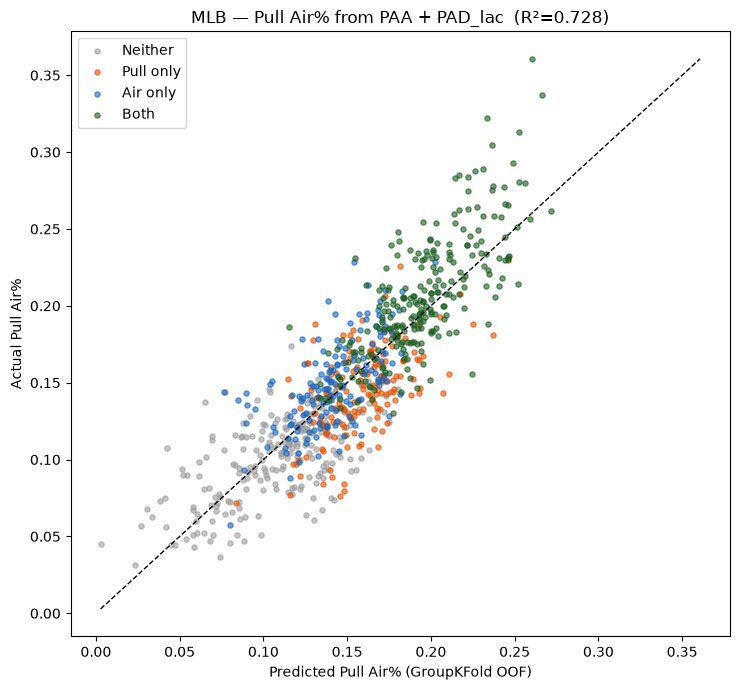

In [27]:
REG_FEATS = ["PAA", "PAD_lac", "is_L", "padlac_x_isL"]
Xr = qual[REG_FEATS].to_numpy(dtype=np.float64)
yr = qual["pull_air_pct"].to_numpy(dtype=np.float64)

pipe_reg = Pipeline([("s", StandardScaler()),
                     ("m", RandomForestRegressor(n_estimators=400, min_samples_leaf=3,
                                                 random_state=42, n_jobs=-1))])
pred_rf_reg = cross_val_predict(pipe_reg, Xr, yr, cv=gkf, groups=groups)
pipe_lin = Pipeline([("s", StandardScaler()), ("m", LinearRegression())])
pred_lin = cross_val_predict(pipe_lin, Xr, yr, cv=gkf, groups=groups)

for name, pred in [("Random Forest", pred_rf_reg), ("Linear", pred_lin)]:
    print(f"{name:<14}  R² {r2_score(yr, pred):.3f}   Spearman ρ {spearmanr(yr, pred)[0]:.3f}")

best_pred = pred_rf_reg if r2_score(yr, pred_rf_reg) >= r2_score(yr, pred_lin) else pred_lin
fig, ax = plt.subplots(figsize=(7.5, 7))
for q in QUAD_ORDER:
    m = qual["quadrant"].values == q
    ax.scatter(best_pred[m], yr[m], s=14, alpha=0.6, color=QUAD_COLORS[q], label=q)
lims = [min(best_pred.min(), yr.min()), max(best_pred.max(), yr.max())]
ax.plot(lims, lims, "k--", lw=1)
ax.set_xlabel("Predicted Pull Air% (GroupKFold OOF)")
ax.set_ylabel("Actual Pull Air%")
ax.set_title(f"MLB — Pull Air% from PAA + PAD_lac  "
            f"(R²={r2_score(yr, best_pred):.3f})")
ax.legend(); plt.tight_layout(); plt.show()

## 12. Reliability — PAD_raw vs PAD_lac (fast joblib pipeline)

The headline validation result.

  BBE≥ 20  PAA=0.621  PAD_raw=0.501  PAD_lac=0.719
  BBE≥ 30  PAA=0.687  PAD_raw=0.519  PAD_lac=0.727
  BBE≥ 50  PAA=0.748  PAD_raw=0.558  PAD_lac=0.772
  BBE≥ 75  PAA=0.792  PAD_raw=0.611  PAD_lac=0.812
  BBE≥100  PAA=0.815  PAD_raw=0.611  PAD_lac=0.836
  BBE≥150  PAA=0.841  PAD_raw=0.623  PAD_lac=0.859
  BBE≥250  PAA=0.850  PAD_raw=0.749  PAD_lac=0.936


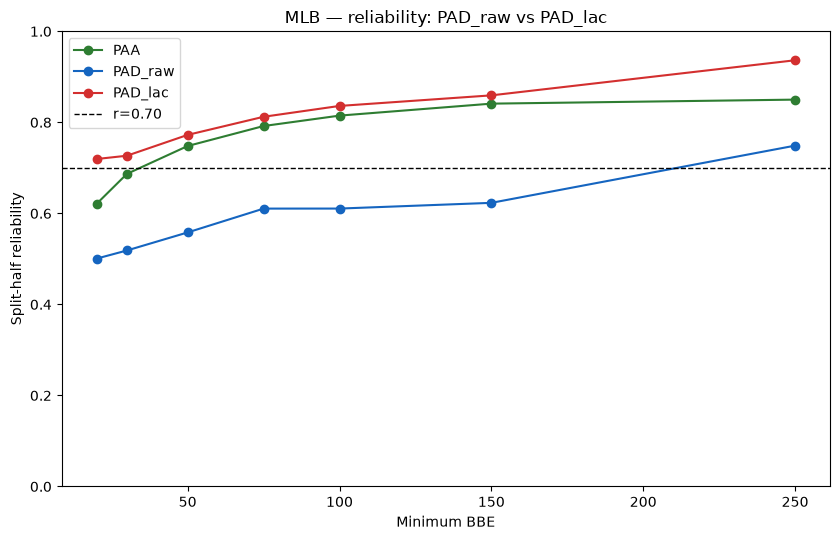

In [28]:
def build_batter_arrays(df, min_bbe):
    arrays = {}
    for (b, s), g in df.groupby(["batter", "season"]):
        gc = g.dropna(subset=["launch_angle", "launch_speed", "spray_pull"])
        if len(gc) < min_bbe * 2:
            continue
        arrays[(b, s)] = (gc["launch_angle"].to_numpy(),
                          gc["launch_speed"].to_numpy(),
                          gc["spray_pull"].to_numpy())
    return arrays

def _one_split(arrays, seed):
    rng = np.random.default_rng(seed)
    rows_h1, rows_h2 = [], []
    for (b, s), (la, ev, sp) in arrays.items():
        n = len(la)
        idx = rng.permutation(n)
        mid = n // 2
        i1, i2 = idx[:mid], idx[mid:]
        m1 = compute_metrics_for_group(la[i1], ev[i1], sp[i1])
        m2 = compute_metrics_for_group(la[i2], ev[i2], sp[i2])
        rows_h1.append((b, s, *m1)); rows_h2.append((b, s, *m2))
    cols = ["batter", "season", "PAA", "PAD_raw", "PAD_lac"]
    h1 = pd.DataFrame(rows_h1, columns=cols)
    h2 = pd.DataFrame(rows_h2, columns=cols)
    merged = h1.merge(h2, on=["batter", "season"], suffixes=("_h1", "_h2"))
    row = {"n_batters": len(merged)}
    for metric in ["PAA", "PAD_raw", "PAD_lac"]:
        pair = merged[[f"{metric}_h1", f"{metric}_h2"]].dropna()
        if len(pair) < 10:
            row[f"{metric}_r_full"] = np.nan
            continue
        r_half = pearsonr(pair[f"{metric}_h1"], pair[f"{metric}_h2"])[0]
        row[f"{metric}_r_full"] = (2 * r_half) / (1 + r_half)
    return row

def split_half_reliability(df, n_splits=30, seed=42, min_bbe=50, n_jobs=-1):
    arrays = build_batter_arrays(df, min_bbe)
    if not arrays:
        return pd.DataFrame()
    results = Parallel(n_jobs=n_jobs)(delayed(_one_split)(arrays, seed + i) for i in range(n_splits))
    return pd.DataFrame([r for r in results if r is not None])

BBE_GRID = [20, 30, 50, 75, 100, 150, 250]
rel_rows = []
for k in BBE_GRID:
    rel = split_half_reliability(mlb, n_splits=30, min_bbe=k)
    if len(rel) == 0:
        continue
    row = {"k": k, "n_batters": rel["n_batters"].median()}
    for metric in ["PAA", "PAD_raw", "PAD_lac"]:
        row[f"{metric}_r_full"] = rel[f"{metric}_r_full"].median()
    rel_rows.append(row)
    print(f"  BBE≥{k:3d}  PAA={row['PAA_r_full']:.3f}  "
          f"PAD_raw={row['PAD_raw_r_full']:.3f}  PAD_lac={row['PAD_lac_r_full']:.3f}")

rel_curve = pd.DataFrame(rel_rows)
fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.plot(rel_curve["k"], rel_curve["PAA_r_full"],     "o-", label="PAA",     color="#2E7D32")
ax.plot(rel_curve["k"], rel_curve["PAD_raw_r_full"], "o-", label="PAD_raw", color="#1565C0")
ax.plot(rel_curve["k"], rel_curve["PAD_lac_r_full"], "o-", label="PAD_lac", color="#D32F2F")
ax.axhline(0.70, color="black", linestyle="--", linewidth=1, label="r=0.70")
ax.set_xlabel("Minimum BBE"); ax.set_ylabel("Split-half reliability")
ax.set_title("MLB — reliability: PAD_raw vs PAD_lac")
ax.set_ylim(0, 1.0); ax.legend()
plt.tight_layout(); plt.show()

## 13. Ruled-Out Alternatives (summary)

Documented for reference — none of these are re-computed in this notebook,
they're recorded results from the investigation that led to PAD_lac.

| Approach | Result | Verdict |
|---|---|---|
| KDE-mode (frequency-weighted spray peak) | Did not beat envelope PAD | Ruled out |
| Joint 2D spray×angle envelope | 2D bins too sparse even at MLB sample sizes; peak locations inconsistent/noisy | Not estimable |
| Foul-ball augmentation | Statcast does not track hit coordinates on fouls | No data |
| Contact-depth front-10% (sign bug) | r=-0.087 vs MAD, worse than random 10% | Sign error |
| Contact-depth front-10% (corrected sign) | r=0.244 vs MAD, beats random baseline (0.217) | Real but small |
| PAD_raw + depth blend | Held-out r 0.489→0.545 | Modest, real gain |
| **PAD_raw + LA-correction (PAD_lac)** | **Held-out r 0.489→0.637; reliability 0.60→0.84 @ BBE≥100** | **Adopted** |
| PAD_raw + depth + LA-correction (3-feature stack) | r=0.654, but depth coefficient ≈ 0 — fully redundant with LA-correction | Simplified to PAD_lac alone |

The depth-based feature became fully redundant once the LA-correction was
added — both were likely capturing the same underlying fact (contact depth
affects both spray *and* launch angle simultaneously), and modeling the
LA↔spray relationship directly captured it more completely.

In [29]:
from scipy.stats import mannwhitneyu

mid = resid_paa[resid_paa["n_bbe"].between(
    resid_paa["n_bbe"].quantile(1/3), resid_paa["n_bbe"].quantile(2/3))]["abs_resid"]
high = resid_paa[resid_paa["n_bbe"] > resid_paa["n_bbe"].quantile(2/3)]["abs_resid"]

stat, p = mannwhitneyu(mid, high)
print(f"PAA Mid vs High tercile: p = {p:.3f}  "
      f"({'no significant difference — genuine plateau' if p > 0.05 else 'still improving'})")

PAA Mid vs High tercile: p = 0.988  (no significant difference — genuine plateau)


## 14. wOBAcon by Quadrant

             n  wOBAcon_weighted   sem
quadrant                              
Neither    246             0.354 0.003
Pull only  154             0.352 0.004
Air only   154             0.374 0.005
Both       246             0.377 0.004


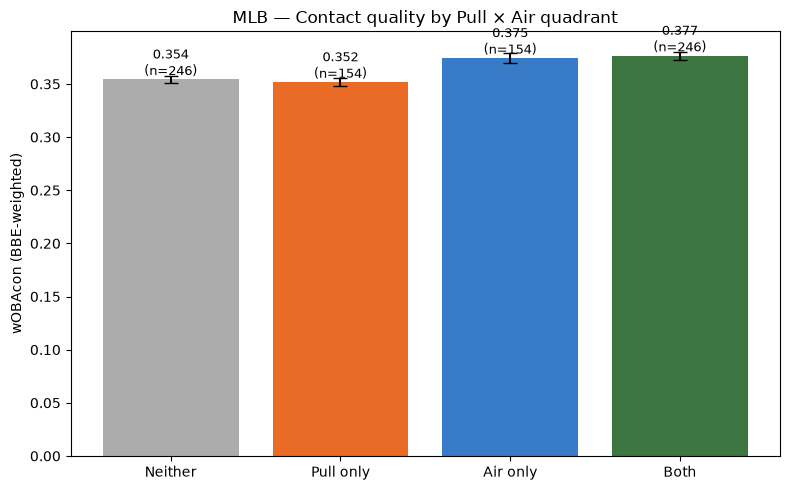

In [30]:
qd = qual.dropna(subset=["quadrant", "wOBAcon"]).copy()
rows = []
for q in QUAD_ORDER:
    sub = qd[qd["quadrant"] == q]
    weighted = np.average(sub["wOBAcon"], weights=sub["n_bbe"])
    sem = sub["wOBAcon"].std() / np.sqrt(len(sub))
    rows.append({"quadrant": q, "n": len(sub), "wOBAcon_weighted": weighted, "sem": sem})
woba_tbl = pd.DataFrame(rows).set_index("quadrant")
print(woba_tbl.round(4).to_string())

fig, ax = plt.subplots(figsize=(8, 5))
xs = np.arange(4)
ax.bar(xs, woba_tbl["wOBAcon_weighted"], yerr=woba_tbl["sem"], capsize=5,
       color=[QUAD_COLORS[q] for q in QUAD_ORDER], alpha=0.85)
ax.set_xticks(xs); ax.set_xticklabels(QUAD_ORDER)
ax.set_ylabel("wOBAcon (BBE-weighted)")
ax.set_title("MLB — Contact quality by Pull × Air quadrant")
for x, (v, n) in enumerate(zip(woba_tbl["wOBAcon_weighted"], woba_tbl["n"])):
    ax.text(x, v + 0.004, f"{v:.3f}\n(n={n})", ha="center", fontsize=9)
plt.tight_layout(); plt.show()

## 15. Year-over-Year Stickiness

In [31]:
seasons = sorted(qual["season"].unique())
stick_rows = []
for y1, y2 in zip(seasons[:-1], seasons[1:]):
    a = qual[qual["season"] == y1][["batter", "pull_air_pct", "PAA", "PAD_raw", "PAD_lac"]]
    b = qual[qual["season"] == y2][["batter", "pull_air_pct", "PAA", "PAD_raw", "PAD_lac"]]
    m = a.merge(b, on="batter", suffixes=("_y1", "_y2"))
    if len(m) < 5:
        continue
    print(f"── {y1} → {y2}  (n={len(m)}) ──")
    for metric in ["pull_air_pct", "PAA", "PAD_raw", "PAD_lac"]:
        pair = m[[f"{metric}_y1", f"{metric}_y2"]].dropna()
        r_s, p_s = spearmanr(pair[f"{metric}_y1"], pair[f"{metric}_y2"])
        stick_rows.append({"pair": f"{y1}→{y2}", "metric": metric, "spearman": r_s, "n": len(pair)})
        print(f"   {metric:<14} Spearman {r_s:+.3f}  (p={p_s:.2e})")

── 2024.0 → 2025.0  (n=307) ──
   pull_air_pct   Spearman +0.741  (p=9.75e-55)
   PAA            Spearman +0.601  (p=1.58e-31)
   PAD_raw        Spearman +0.486  (p=1.40e-19)
   PAD_lac        Spearman +0.692  (p=5.47e-45)


## 16. Final Deliverable

In [32]:
out = qual[["batter", "season", "stand", "n_bbe",
            "pull_pct", "air_ball_pct", "pull_air_pct",
            "PAA", "PAD_raw", "PAD_lac", "quadrant",
            "mean_ev", "ev_90", "hard_hit_pct", "wOBAcon"]].copy()
out["pred_pull_air_pct"] = best_pred
out = out.sort_values("pull_air_pct", ascending=False).reset_index(drop=True)

print("── Top 15 by Pull Air% ──")
print(out.head(15).to_string(index=False))

Path("output").mkdir(exist_ok=True)
out.to_csv("output/mlb_pull_air_quadrants_padlac.csv", index=False)
print(f"\nSaved → output/mlb_pull_air_quadrants_padlac.csv   ({len(out)} batter-seasons)")

── Top 15 by Pull Air% ──
    batter   season stand   n_bbe  pull_pct  air_ball_pct  pull_air_pct    PAA  PAD_raw  PAD_lac quadrant  mean_ev   ev_90  hard_hit_pct  wOBAcon  pred_pull_air_pct
670623.000 2025.000     R 305.000     0.541         0.702         0.361 15.889   17.793   12.063     Both   87.378 102.500         0.338    0.376              0.260
663728.000 2025.000     L 418.000     0.529         0.722         0.337 23.675   23.556   10.868     Both   91.307 106.930         0.495    0.503              0.266
670623.000 2024.000     R 447.000     0.488         0.702         0.322 14.438   21.345   10.150     Both   85.098 100.540         0.275    0.330              0.234
656555.000 2025.000     R 195.000     0.487         0.692         0.313 19.757   14.608    9.809     Both   89.913 103.560         0.462    0.395              0.252
641343.000 2024.000     L 184.000     0.484         0.723         0.304 22.474   14.694    8.484     Both   88.497 103.970         0.429    0.388    